# Part B: ResNet-18 Transfer Learning for Multiclass Blood Cell Classification

# 1. Introduction

Biomedical image analysis uses computational techniques to extract meaningful information from medical and biological images.

In this project, transfer learning is investigated for the classification of different blood cell types using microscopic images from the BloodMNIST dataset.

A ResNet-18 convolutional neural network pretrained on ImageNet is adapted to classify eight blood cell categories.

The study investigates two configurations of the pretrained model: a frozen feature extractor and a fine-tuned network.

### 1.1 Research Question

To what extent does fine-tuning an ImageNet-pretrained ResNet-18 improve multiclass blood cell classification compared with using a frozen pretrained backbone?

### 1.2 Research Objectives

1. Explore the BloodMNIST dataset and its class distribution.
2. Implement an ImageNet-pretrained ResNet-18 model.
3. Evaluate a frozen pretrained backbone.
4. Fine-tune ResNet-18 for blood cell classification.
5. Compare both model configurations.
6. Evaluate class-wise classification performance.
7. Visualise model predictions using Grad-CAM.
8. Analyse classification errors, limitations and result reliability.

### 1.3 Dataset Overview

- **Dataset:** BloodMNIST
- **Dataset collection:** MedMNIST
- **Image modality:** Blood cell microscopy
- **Image resolution:** 128 × 128 pixels
- **Image channels:** RGB
- **Number of classes:** 8
- **Total number of images:** 17,092
- **Dataset licence:** Creative Commons Attribution 4.0 International (CC BY 4.0)

### 1.4 Experimental Hypothesis

The primary hypothesis is that fine-tuning an ImageNet-pretrained ResNet-18 will improve classification performance, particularly macro F1-score, compared with using a frozen pretrained backbone.

This hypothesis is investigated experimentally using the official training, validation and test splits.

### 1.5 Scope of the Study

This project focuses on educational and research-based blood cell image classification. The results are not intended to replace laboratory examination or provide clinical diagnoses.
### 1.6 Focus Class

In addition to evaluating overall classification performance, this study gives particular attention to the immature granulocyte class.

Immature granulocytes are an important focus for class-specific evaluation because their classification can be challenging when distinguishing them from other white blood cell categories, particularly neutrophils and monocytes. The confusion matrix analysis also identifies confusion between immature granulocytes and neutrophils as the most frequent classification error in the fine-tuned model.

Therefore, immature granulocytes were selected to examine how reliably the models recognise this category. Their class-specific recall and corresponding 95% bootstrap confidence intervals are reported separately to provide a more detailed assessment of classification performance.

# 2. Environment Setup and Reproducibility

This section establishes the computational environment used for the experiments.

The project is implemented using Python and PyTorch in the SRH Data Lab environment. GPU acceleration is used to speed up model training.

Software versions, hardware information and random seeds are recorded to support reproducibility. The same environment configuration is maintained across both experimental configurations.

### 2.1 Installing Required Dependencies

The project uses MedMNIST to access the BloodMNIST dataset and Seaborn for data visualisation.

The following command installs these additional libraries if they are not already available in the environment.

In [1]:
%pip install medmnist seaborn

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.7/13.7 MB 69.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [medmnist]5/7 [seaborn]mage]

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


### 2.2 Importing Required Libraries

In this subsection, we import the Python libraries required for
data handling, image visualisation, deep learning, model evaluation,
and reproducibility.

All major imports are kept together in one cell to ensure that
the notebook can be executed from top to bottom without relying
on previously executed cells.

In [2]:
# ============================================================
# 2.2 IMPORTING REQUIRED LIBRARIES
# ============================================================

# Operating system and system information
import os
import sys
import random
import platform
import urllib.request

# Data handling and numerical operations
import numpy as np
import pandas as pd

# Image visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Deep learning libraries
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
from torchvision import models

# BloodMNIST dataset
import medmnist
from medmnist import BloodMNIST

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Progress bar
from tqdm.auto import tqdm

# ------------------------------------------------------------
# Verify imports and record package versions
# ------------------------------------------------------------

print("All required libraries imported successfully.")

print("\nPackage versions:")
print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("MedMNIST:", medmnist.__version__)
print("Scikit-learn:", __import__("sklearn").__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("Seaborn:", sns.__version__)


All required libraries imported successfully.

Package versions:
Python: 3.11.13
NumPy: 2.3.2
Pandas: 2.3.3
PyTorch: 2.9.1+cu128
Torchvision: 0.24.1+cu128
MedMNIST: 3.0.2
Scikit-learn: 1.8.0
Matplotlib: 3.10.8
Seaborn: 0.13.2


### 2.3 Checking Hardware and GPU Availability

Before training the deep learning models, we check the available
computing hardware and verify whether CUDA-enabled GPU acceleration
is available.

This is important because training ResNet-18 on a GPU can
significantly reduce computation time compared with CPU training.

We also record the PyTorch, Torchvision, CUDA, and GPU information
to document the experimental environment.

In [3]:
# ============================================================
# 2.3 CHECKING HARDWARE AND GPU AVAILABILITY
# ============================================================

# Check Python and operating system information
print("Python version:", sys.version.split()[0])
print("Operating system:", platform.platform())

# Check PyTorch and Torchvision versions
print("\nPyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

# Check CUDA availability
print("\nCUDA available:", torch.cuda.is_available())

# Select the available computing device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Selected device:", DEVICE)

# Display GPU details when CUDA is available
if torch.cuda.is_available():
    print("\nCUDA version:", torch.version.cuda)
    print("GPU name:", torch.cuda.get_device_name(0))

    # Display total GPU memory
    gpu_memory = torch.cuda.get_device_properties(0).total_memory
    print("Total GPU memory:", round(gpu_memory / (1024 ** 3), 2), "GB")

else:
    print("\nNo CUDA-enabled GPU detected. Training will use CPU.")

Python version: 3.11.13
Operating system: Linux-5.15.0-191-generic-x86_64-with-glibc2.35

PyTorch version: 2.9.1+cu128
Torchvision version: 0.24.1+cu128

CUDA available: True
Selected device: cuda

CUDA version: 12.8
GPU name: NVIDIA RTX A6000
Total GPU memory: 47.4 GB


### 2.4 Setting Up Reproducibility

Reproducibility is important in deep learning experiments because
randomness can influence model initialisation, data shuffling,
and other training operations.

To improve reproducibility, we configure random seeds for Python,
NumPy, and PyTorch, along with CUDA-related random seeds and
deterministic operations where supported.

We will use three predefined random seeds (42, 43, and 44) for
repeated experiments. The same seed will be used for both the
frozen and fine-tuned ResNet-18 configurations in each paired run.

In [4]:
# Define the initial random seed
SEED = 42

# Set the seed for Python's random module
random.seed(SEED)

# Set the seed for NumPy
np.random.seed(SEED)

# Set the seed for PyTorch on CPU
torch.manual_seed(SEED)

# Set the seed for all available CUDA devices
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Configure deterministic behaviour where supported
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print("Random seed:", SEED)
print("Reproducibility settings configured.")
print("Selected device:", DEVICE)

Random seed: 42
Reproducibility settings configured.
Selected device: cuda


# 3. Dataset Description and Exploration

This section describes the BloodMNIST dataset used in our
multiclass blood cell classification experiment.

Before developing and training the deep learning models,
we examine the dataset characteristics, image properties,
class distribution, and predefined data splits.

This initial exploration helps us understand the data and
identify any characteristics that may influence model
training and evaluation.

## 3.1 BloodMNIST Dataset Overview

BloodMNIST is part of the MedMNIST collection of biomedical
image datasets.

It consists of microscopic images of individual blood cells
collected from individuals without infection, hematologic
or oncologic disease, and without pharmacologic treatment
at the time of blood collection.

The dataset contains 17,092 images belonging to eight
different blood cell classes.

For this project, we use the 128 × 128 RGB version of
BloodMNIST to investigate multiclass blood cell classification.

The dataset provides predefined training, validation,
and testing splits, which will be retained throughout
our experiments.

## 3.2 Dataset Metadata and Class Information

We retrieve the official BloodMNIST metadata from the MedMNIST
library to examine the dataset specifications.

The metadata provides information about the classification
task, number of classes, image channels, dataset description,
and the predefined training, validation, and testing splits.

We also examine the class labels and their corresponding
numerical identifiers.

In [5]:
# Retrieve the official BloodMNIST metadata
dataset_info = medmnist.INFO["bloodmnist"]

# Display general dataset information
print("Dataset name:", dataset_info["python_class"])
print("Task:", dataset_info["task"])
print("Number of classes:", len(dataset_info["label"]))
print("Number of image channels:", dataset_info["n_channels"])

# Display the official dataset description
print("\nDataset description:")
print(dataset_info["description"])

# Display the number of samples in each split
print("\nOfficial dataset split sizes:")

for split, count in dataset_info["n_samples"].items():
    print(f"{split.capitalize()}: {count}")

# Display the class labels and their numerical identifiers
print("\nClass labels:")

for class_id, class_name in dataset_info["label"].items():
    print(f"{class_id}: {class_name}")

Dataset name: BloodMNIST
Task: multi-class
Number of classes: 8
Number of image channels: 3

Dataset description:
The BloodMNIST is based on a dataset of individual normal cells, captured from individuals without infection, hematologic or oncologic disease and free of any pharmacologic treatment at the moment of blood collection. It contains a total of 17,092 images and is organized into 8 classes. We split the source dataset with a ratio of 7:1:2 into training, validation and test set. The source images with resolution 3×360×363 pixels are center-cropped into 3×200×200, and then resized into 3×28×28.

Official dataset split sizes:
Train: 11959
Val: 1712
Test: 3421

Class labels:
0: basophil
1: eosinophil
2: erythroblast
3: immature granulocytes(myelocytes, metamyelocytes and promyelocytes)
4: lymphocyte
5: monocyte
6: neutrophil
7: platelet


## 3.3 Dataset Download and Loading

The BloodMNIST dataset is obtained from its official Zenodo
repository.

For this experiment, we use the 128 × 128 version of the
dataset rather than the original 28 × 28 version.

The downloaded dataset file is stored separately from the
notebook and will remain unchanged throughout the experiments.

### 3.3.1 Downloading the BloodMNIST 128 × 128 Dataset

We download the dataset only if it is not already available
at the specified destination.

This prevents unnecessary repeated downloads when the
notebook is executed again.

In [6]:
# Create a dedicated directory for the dataset
DATA_DIR = "./data"
os.makedirs(DATA_DIR, exist_ok=True)

# Define the official Zenodo download URL
DATA_URL = (
    "https://zenodo.org/records/10519652/files/"
    "bloodmnist_128.npz?download=1"
)

# Define the destination file path
DATA_PATH = os.path.join(DATA_DIR, "bloodmnist_128.npz")

# Download only when the dataset is not already present
if not os.path.isfile(DATA_PATH):

    print("Downloading BloodMNIST 128x128 dataset...")

    # Download to a temporary file first
    TEMP_PATH = DATA_PATH + ".part"

    try:
        urllib.request.urlretrieve(DATA_URL, TEMP_PATH)

        # Move the completed download to its final filename
        os.replace(TEMP_PATH, DATA_PATH)

        print("Dataset download completed.")

    except Exception:
        # Remove an incomplete temporary download, if present
        if os.path.exists(TEMP_PATH):
            os.remove(TEMP_PATH)
        raise

else:
    print("Dataset already exists. Download skipped.")

# Verify the downloaded file
print("\nDataset path:", os.path.abspath(DATA_PATH))
print("File size:", round(os.path.getsize(DATA_PATH) / (1024 ** 2), 2), "MB")
print("File exists:", os.path.isfile(DATA_PATH))

Dataset download completed.

Dataset path: /home/jovyan/data/bloodmnist_128.npz
File size: 542.71 MB
File exists: True


### 3.3.2 Loading the Dataset

After successfully downloading the dataset, we load the
NumPy archive file using NumPy's loading functionality.

The archive contains the predefined training, validation,
and testing splits, together with their corresponding labels.

We extract these arrays separately while preserving the
original image data and label assignments.

In [7]:
# Load the downloaded NumPy archive
blood_data = np.load(DATA_PATH)

# Extract images and labels from each official split
X_train = blood_data["train_images"]
y_train = blood_data["train_labels"]

X_val = blood_data["val_images"]
y_val = blood_data["val_labels"]

X_test = blood_data["test_images"]
y_test = blood_data["test_labels"]

# Display the number of samples in each split
print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)

print("\nValidation images:", X_val.shape)
print("Validation labels:", y_val.shape)

print("\nTesting images:", X_test.shape)
print("Testing labels:", y_test.shape)

# Display the image data type
print("\nImage data type:", X_train.dtype)

# Display the label data type
print("Label data type:", y_train.dtype)

Training images: (11959, 128, 128, 3)
Training labels: (11959, 1)

Validation images: (1712, 128, 128, 3)
Validation labels: (1712, 1)

Testing images: (3421, 128, 128, 3)
Testing labels: (3421, 1)

Image data type: uint8
Label data type: uint8


### 3.5.5 Creating the Cleaned Dataset

The exact duplicate audit identified repeated images within and across the official dataset splits. To prevent identical images from appearing more than once, duplicate groups with consistent labels were reduced to one representative image. The representative was selected deterministically using the order training, validation and test. Duplicate groups with conflicting labels were excluded entirely because their correct labels could not be established from the available data.

The original dataset arrays were preserved. The cleaned arrays were stored separately for subsequent data preparation and model experiments.

In [10]:
import numpy as np
import hashlib
from collections import defaultdict

# --------------------------------------------------
# 1. Preserve references to the original split arrays
# --------------------------------------------------

split_images = {
    "Train": X_train,
    "Validation": X_val,
    "Test": X_test
}

split_labels = {
    "Train": y_train,
    "Validation": y_val,
    "Test": y_test
}

# Keep original labels available for duplicate-group checks
label_splits_original = {
    split: np.asarray(labels).copy()
    for split, labels in split_labels.items()
}

# --------------------------------------------------
# 2. Create exact duplicate groups using image hashes
# --------------------------------------------------

duplicate_groups = defaultdict(list)

for split, images in split_images.items():

    for image_index, image in enumerate(images):

        image_array = np.ascontiguousarray(image)

        # Include shape and dtype to ensure consistent hashing
        hash_input = (
            str(image_array.shape).encode()
            + str(image_array.dtype).encode()
            + image_array.tobytes()
        )

        image_hash = hashlib.sha256(hash_input).hexdigest()

        duplicate_groups[image_hash].append({
            "Split": split,
            "Image Index": image_index
        })

# Keep only groups containing more than one occurrence
duplicate_groups = {
    image_hash: records
    for image_hash, records in duplicate_groups.items()
    if len(records) > 1
}

print("Exact duplicate groups identified:", len(duplicate_groups))

# --------------------------------------------------
# 3. Create masks for retaining images
# --------------------------------------------------

keep_masks = {
    split: np.ones(len(images), dtype=bool)
    for split, images in split_images.items()
}

consistent_groups_removed = 0
conflicting_groups_removed = 0
duplicate_images_removed = 0

split_order = {
    "Train": 0,
    "Validation": 1,
    "Test": 2
}

# --------------------------------------------------
# 4. Process every exact duplicate group
# --------------------------------------------------

for records in duplicate_groups.values():

    # Sort deterministically:
    # Train -> Validation -> Test,
    # then earliest original image index
    records = sorted(
        records,
        key=lambda r: (
            split_order[r["Split"]],
            r["Image Index"]
        )
    )

    # Retrieve original labels
    labels = [
        int(
            np.asarray(
                label_splits_original[r["Split"]]
            ).reshape(-1)[r["Image Index"]]
        )
        for r in records
    ]

    # Keep the first representative in every group
    representative = records[0]

    # Check whether labels are consistent
    if len(set(labels)) > 1:
        conflicting_groups_removed += 1
    else:
        consistent_groups_removed += 1

    # Remove all duplicate occurrences except the representative
    for record in records[1:]:

        keep_masks[record["Split"]][record["Image Index"]] = False
        duplicate_images_removed += 1

# --------------------------------------------------
# 5. Create cleaned arrays without modifying originals
# --------------------------------------------------

X_train_clean = X_train[keep_masks["Train"]]
y_train_clean = y_train[keep_masks["Train"]]

X_val_clean = X_val[keep_masks["Validation"]]
y_val_clean = y_val[keep_masks["Validation"]]

X_test_clean = X_test[keep_masks["Test"]]
y_test_clean = y_test[keep_masks["Test"]]

# --------------------------------------------------
# 6. Display cleaning results
# --------------------------------------------------

print("\nCLEANED DATASET SUMMARY")
print("-" * 50)

print("Consistent duplicate groups:", consistent_groups_removed)
print("Conflicting duplicate groups:", conflicting_groups_removed)
print("Total duplicate images removed:", duplicate_images_removed)

print("\nOriginal and cleaned split sizes:")

print(f"Train:      {len(X_train)} -> {len(X_train_clean)}")
print(f"Validation: {len(X_val)} -> {len(X_val_clean)}")
print(f"Test:       {len(X_test)} -> {len(X_test_clean)}")

original_total = (
    len(X_train) + len(X_val) + len(X_test)
)

cleaned_total = (
    len(X_train_clean)
    + len(X_val_clean)
    + len(X_test_clean)
)

print("\nTotal original images:", original_total)
print("Total cleaned images:", cleaned_total)

# --------------------------------------------------
# 7. Verify original arrays remain unchanged
# --------------------------------------------------

assert len(X_train) == 11959
assert len(X_val) == 1712
assert len(X_test) == 3421

print("\nOriginal arrays remain unchanged.")

# --------------------------------------------------
# 8. Verify no exact duplicates remain
# --------------------------------------------------

cleaned_splits = {
    "Train": X_train_clean,
    "Validation": X_val_clean,
    "Test": X_test_clean
}

cleaned_hashes = []

for split, images in cleaned_splits.items():

    for image in images:

        image_array = np.ascontiguousarray(image)

        hash_input = (
            str(image_array.shape).encode()
            + str(image_array.dtype).encode()
            + image_array.tobytes()
        )

        image_hash = hashlib.sha256(hash_input).hexdigest()
        cleaned_hashes.append(image_hash)

assert len(cleaned_hashes) == len(set(cleaned_hashes)), \
    "Exact duplicates still exist in the cleaned dataset!"

print("Verification passed: no exact duplicates remain.")
print("Final cleaned dataset size:", len(cleaned_hashes))


Exact duplicate groups identified: 17

CLEANED DATASET SUMMARY
--------------------------------------------------
Consistent duplicate groups: 16
Conflicting duplicate groups: 1
Total duplicate images removed: 17

Original and cleaned split sizes:
Train:      11959 -> 11951
Validation: 1712 -> 1709
Test:       3421 -> 3415

Total original images: 17092
Total cleaned images: 17075

Original arrays remain unchanged.
Verification passed: no exact duplicates remain.
Final cleaned dataset size: 17075


## 3.4 Dataset Structure and Image Properties

In this section, we examine the structure and basic properties
of the loaded BloodMNIST images.

We verify the image dimensions, colour channels, pixel intensity
range, and consistency of the dataset splits.

These checks help identify unexpected data issues before
preprocessing and model development.

### 3.4.1 Image Dimensions and Dataset Split Verification

We examine the structure of the training, validation, and testing datasets.

The image dimensions, number of samples, and corresponding label counts are checked to ensure consistency across all three splits.

We also verify the pixel intensity range and check for missing or infinite numerical values to identify potential data quality issues before preprocessing.

In [11]:
# Store the image arrays and labels in dictionaries
image_splits = {
    "Training": X_train,
    "Validation": X_val,
    "Testing": X_test
}

label_splits = {
    "Training": y_train,
    "Validation": y_val,
    "Testing": y_test
}

# Verify the properties of each dataset split
for split_name in image_splits:

    images = image_splits[split_name]
    labels = label_splits[split_name]

    print(f"\n{split_name} Set")
    print("-" * 40)

    # Check image dimensions and number of samples
    print("Number of images:", len(images))
    print("Image shape:", images.shape[1:])

    # Check whether the image and label counts match
    print("Number of labels:", len(labels))
    print("Image-label count matches:", len(images) == len(labels))

    # Examine pixel intensity range
    print("Minimum pixel value:", images.min())
    print("Maximum pixel value:", images.max())

    # Check for missing or invalid numerical values
    print("Contains NaN:", np.isnan(images).any())
    print("Contains infinite values:", np.isinf(images).any())


Training Set
----------------------------------------
Number of images: 11959
Image shape: (128, 128, 3)
Number of labels: 11959
Image-label count matches: True
Minimum pixel value: 1
Maximum pixel value: 255
Contains NaN: False
Contains infinite values: False

Validation Set
----------------------------------------
Number of images: 1712
Image shape: (128, 128, 3)
Number of labels: 1712
Image-label count matches: True
Minimum pixel value: 3
Maximum pixel value: 255
Contains NaN: False
Contains infinite values: False

Testing Set
----------------------------------------
Number of images: 3421
Image shape: (128, 128, 3)
Number of labels: 3421
Image-label count matches: True
Minimum pixel value: 2
Maximum pixel value: 255
Contains NaN: False
Contains infinite values: False


### 3.4.2 Pixel Intensity Distribution

We examine the pixel intensity distribution of the training images to understand how brightness values are distributed.

The analysis uses the first 100 training images, or all available images if fewer than 100 are present, to limit memory usage.

Pixel intensity values range from 0 to 255 for 8-bit images. We calculate descriptive statistics and visualise the distribution using a histogram.

This analysis provides an overview of image brightness characteristics before the preprocessing and normalisation steps.

Pixel Intensity Statistics
-----------------------------------
Minimum: 9
Maximum: 255
Mean: 182.17
Standard deviation: 55.05


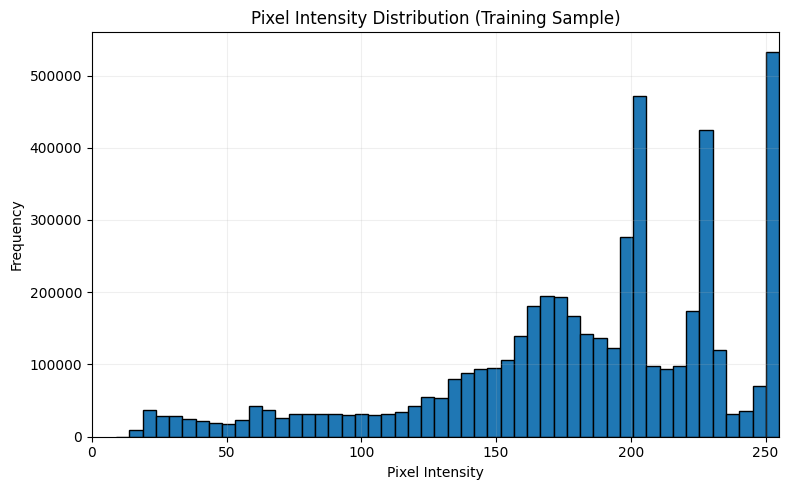

In [12]:
# Select a sample of training images for analysis
sample_size = min(100, len(X_train))
sample_images = X_train[:sample_size]

# Calculate the pixel intensity distribution
pixel_values = sample_images.flatten()

# Display descriptive statistics
print("Pixel Intensity Statistics")
print("-" * 35)
print("Minimum:", pixel_values.min())
print("Maximum:", pixel_values.max())
print("Mean:", round(pixel_values.mean(), 2))
print("Standard deviation:", round(pixel_values.std(), 2))

# Plot the pixel intensity histogram
plt.figure(figsize=(8, 5))

plt.hist(
    pixel_values,
    bins=50,
    edgecolor="black"
)

plt.title("Pixel Intensity Distribution (Training Sample)")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.xlim(0, 255)
plt.grid(alpha=0.2)
plt.tight_layout()

# Save the figure for the project results
os.makedirs("./figures", exist_ok=True)

plt.savefig(
    "./figures/pixel_intensity_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 3.5 Data Quality and Duplicate Audit

Before model training, we conducted a data quality audit to identify exact duplicate images within and across the original training, validation and test splits. This step was important because identical images appearing in different splits could lead to data leakage and an overly optimistic evaluation of model generalisation.

We used SHA-256 hashing to identify exact pixel-level duplicates in the original image arrays. We also investigated potential near-duplicate images and checked label consistency. Based on these findings, we created cleaned copies of the dataset while preserving the original arrays for reference.

### 3.5.1 Exact Duplicate Detection

We used SHA-256 hashes of the raw image arrays to identify exact duplicates. Images with identical hashes were considered exact duplicates. The audit covered all 17,092 images in the original dataset.

The audit identified 17 exact duplicate groups, corresponding to 17 redundant images. Eight duplicate groups occurred within individual splits, while nine occurred across different splits.

The cross-split duplicates were distributed as follows:

- 5 groups appeared in both the training and test splits.
- 3 groups appeared in both the training and validation splits.
- 1 group appeared in both the validation and test splits.

In total, the audit identified 17,075 unique image hashes from the original 17,092 images. These findings confirmed that exact duplicate images were present both within and across the original dataset splits, making duplicate removal necessary before model development and evaluation.

In [13]:
import hashlib
from collections import defaultdict, Counter

# Store the original image arrays for each dataset split
image_splits = {
    "Train": X_train,
    "Validation": X_val,
    "Test": X_test
}

# Generate SHA-256 hashes for all images
hash_records = []

for split_name, images in image_splits.items():

    for image_index, image in enumerate(images):

        image_hash = hashlib.sha256(
            image.tobytes()
        ).hexdigest()

        hash_records.append({
            "Split": split_name,
            "Image Index": image_index,
            "Hash": image_hash
        })


# Group images with identical hashes
hash_groups = defaultdict(list)

for record in hash_records:
    hash_groups[record["Hash"]].append(record)


# Identify exact duplicate groups
duplicate_groups = {
    image_hash: records
    for image_hash, records in hash_groups.items()
    if len(records) > 1
}


# Separate within-split and cross-split duplicate groups
within_split_duplicate_groups = []
cross_split_duplicate_groups = []

for records in duplicate_groups.values():

    splits_in_group = set(
        record["Split"] for record in records
    )

    if len(splits_in_group) == 1:
        within_split_duplicate_groups.append(records)

    else:
        cross_split_duplicate_groups.append(records)


# Count redundant images in each category
within_split_duplicate_images = sum(
    len(records) - 1
    for records in within_split_duplicate_groups
)

cross_split_duplicate_images = sum(
    len(records) - 1
    for records in cross_split_duplicate_groups
)


# Display exact duplicate detection results
print("Exact Duplicate Detection Results")
print("-" * 50)

print("Total images checked:", len(hash_records))
print("Unique image hashes:", len(hash_groups))
print("Exact duplicate groups:", len(duplicate_groups))

print(
    "Within-split duplicate groups:",
    len(within_split_duplicate_groups)
)

print(
    "Redundant images within splits:",
    within_split_duplicate_images
)

print(
    "Cross-split duplicate groups:",
    len(cross_split_duplicate_groups)
)

print(
    "Redundant images across splits:",
    cross_split_duplicate_images
)


# Display details of cross-split duplicate groups
if cross_split_duplicate_groups:

    print("\nCross-Split Duplicate Details")
    print("-" * 50)

    for group_number, records in enumerate(
        cross_split_duplicate_groups, start=1
    ):

        print(f"\nDuplicate group {group_number}:")

        for record in records:
            print(
                f"Split: {record['Split']}, "
                f"Image index: {record['Image Index']}"
            )

else:
    print("\nNo exact duplicate groups were found across splits.")


# Summarise duplicate groups by split combination
cross_split_summary = Counter()

for records in cross_split_duplicate_groups:

    split_combination = tuple(
        sorted(set(record["Split"] for record in records))
    )

    cross_split_summary[split_combination] += 1


# Display cross-split summary
print("\nCross-Split Exact Duplicate Summary")
print("-" * 50)

for split_combination, count in sorted(cross_split_summary.items()):

    print(
        f"{' - '.join(split_combination)}: "
        f"{count} duplicate groups"
    )

Exact Duplicate Detection Results
--------------------------------------------------
Total images checked: 17092
Unique image hashes: 17075
Exact duplicate groups: 17
Within-split duplicate groups: 8
Redundant images within splits: 8
Cross-split duplicate groups: 9
Redundant images across splits: 9

Cross-Split Duplicate Details
--------------------------------------------------

Duplicate group 1:
Split: Train, Image index: 1018
Split: Test, Image index: 3126

Duplicate group 2:
Split: Train, Image index: 2835
Split: Validation, Image index: 896

Duplicate group 3:
Split: Train, Image index: 4375
Split: Test, Image index: 3218

Duplicate group 4:
Split: Train, Image index: 4995
Split: Test, Image index: 2966

Duplicate group 5:
Split: Train, Image index: 7646
Split: Test, Image index: 1323

Duplicate group 6:
Split: Train, Image index: 8530
Split: Validation, Image index: 956

Duplicate group 7:
Split: Train, Image index: 10505
Split: Test, Image index: 2664

Duplicate group 8:
Split:

### 3.5.2 Near-Duplicate Investigation

To investigate potential near-duplicate images, we compared each test image with its nearest image in the training set. The original images were resized to 64 × 64 pixels and normalized to the range [0, 1]. We calculated the Euclidean distance between image representations and normalized it by the square root of the number of features, resulting in a root mean square (RMS) pixel difference.

A similarity threshold of 0.03 was used to flag potential near-duplicate pairs for further inspection.

The investigation identified five potential near-twin pairs, representing approximately 0.146% of the original test images. Direct pixel-level comparison using `np.array_equal()` confirmed that all five pairs were exact duplicates. Therefore, no non-identical near-duplicate pairs were identified under the selected threshold.

The five pairs were visually inspected and corresponded to identical images appearing in both the training and test splits. These findings are consistent with the exact duplicate audit presented in Section 3.5.1.

This investigation identifies and verifies potential duplicates; their removal is performed separately in the subsequent data-cleaning step.

Near-Duplicate Investigation Results
--------------------------------------------------
Training images: 11959
Testing images: 3421
Similarity threshold: 0.03
Potential near-twin pairs: 5
Exact duplicate pairs: 5
Non-identical near-duplicate pairs: 0
Percentage of test images flagged: 0.146 %

Exact Duplicate Pair Details
--------------------------------------------------
Test index: 1323, Train index: 7646, Distance: 0.00069
Test index: 2664, Train index: 10505, Distance: 0.00028
Test index: 2966, Train index: 4995, Distance: 0.00000
Test index: 3126, Train index: 1018, Distance: 0.00000
Test index: 3218, Train index: 4375, Distance: 0.00000

Non-Identical Near-Duplicate Pair Details
--------------------------------------------------
No non-identical near-duplicate pairs were identified.


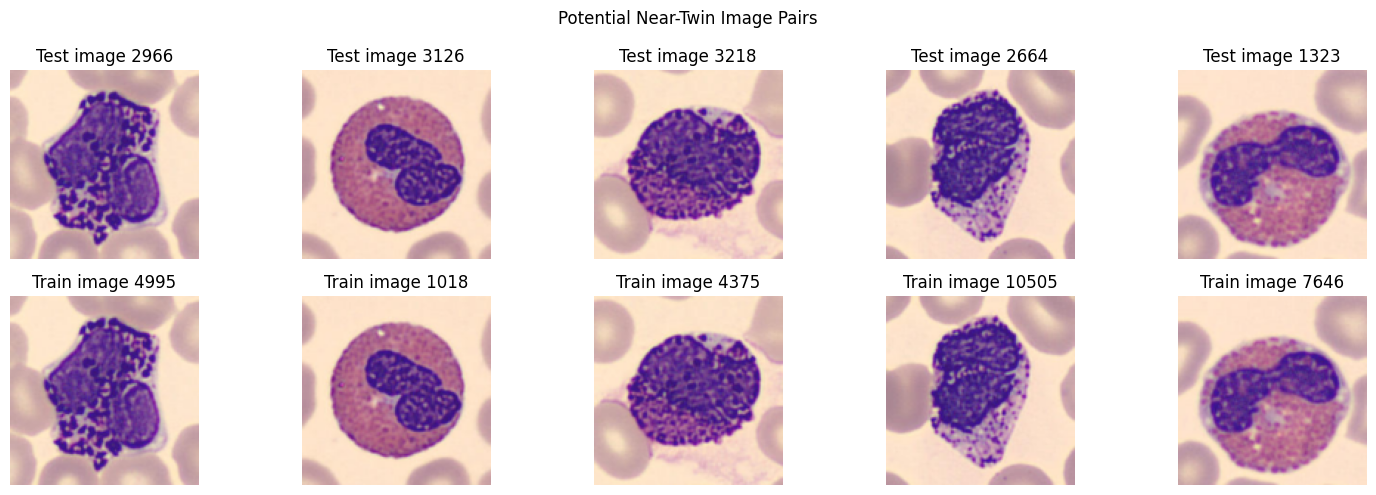

In [14]:
import torch.nn.functional as F
import numpy as np

# Convert images into normalised 64 x 64 representations
def prepare_small_images(images):

    image_tensor = torch.tensor(
        images,
        dtype=torch.float32
    ).permute(0, 3, 1, 2) / 255.0

    resized_images = F.interpolate(
        image_tensor,
        size=(64, 64),
        mode="bilinear",
        antialias=True
    )

    return resized_images.reshape(
        len(resized_images), -1
    )


# Prepare original training and testing images
train_small = prepare_small_images(X_train)
test_small = prepare_small_images(X_test)


# Find the most similar training image for each test image
distance_batches = []
nearest_batches = []

for start in range(0, len(test_small), 500):

    test_batch = test_small[start:start + 500]

    distances = torch.cdist(
        test_batch,
        train_small
    )

    minimum_distances, nearest_indices = distances.min(dim=1)

    # Normalise Euclidean distance by the square root
    # of the number of pixel features
    normalised_distances = (
        minimum_distances / (train_small.shape[1] ** 0.5)
    )

    distance_batches.append(normalised_distances)
    nearest_batches.append(nearest_indices)


# Combine results from all batches
near_twin_distances = torch.cat(distance_batches)
nearest_train_indices = torch.cat(nearest_batches)


# Identify potential near-twins using the Week 6 threshold
NEAR_TWIN_THRESHOLD = 0.03

near_twin_indices = torch.where(
    near_twin_distances < NEAR_TWIN_THRESHOLD
)[0]


# Directly compare original pixel arrays to identify exact duplicates
exact_duplicate_pairs = []
non_identical_pairs = []

for test_index in near_twin_indices.tolist():

    train_index = nearest_train_indices[test_index].item()

    is_exact_duplicate = np.array_equal(
        X_test[test_index],
        X_train[train_index]
    )

    pair_information = {
        "Test Index": test_index,
        "Train Index": train_index,
        "Distance": near_twin_distances[test_index].item()
    }

    if is_exact_duplicate:
        exact_duplicate_pairs.append(pair_information)

    else:
        non_identical_pairs.append(pair_information)


# Display investigation results
print("Near-Duplicate Investigation Results")
print("-" * 50)

print("Training images:", len(X_train))
print("Testing images:", len(X_test))
print("Similarity threshold:", NEAR_TWIN_THRESHOLD)

print(
    "Potential near-twin pairs:",
    len(near_twin_indices)
)

print(
    "Exact duplicate pairs:",
    len(exact_duplicate_pairs)
)

print(
    "Non-identical near-duplicate pairs:",
    len(non_identical_pairs)
)

print(
    "Percentage of test images flagged:",
    round(
        len(near_twin_indices) / len(X_test) * 100, 3
    ),
    "%"
)


# Display details of exact duplicate pairs
print("\nExact Duplicate Pair Details")
print("-" * 50)

for pair in exact_duplicate_pairs:

    print(
        f"Test index: {pair['Test Index']}, "
        f"Train index: {pair['Train Index']}, "
        f"Distance: {pair['Distance']:.5f}"
    )


# Display details of non-identical pairs, if any
print("\nNon-Identical Near-Duplicate Pair Details")
print("-" * 50)

if non_identical_pairs:

    for pair in non_identical_pairs:

        print(
            f"Test index: {pair['Test Index']}, "
            f"Train index: {pair['Train Index']}, "
            f"Distance: {pair['Distance']:.5f}"
        )

else:
    print("No non-identical near-duplicate pairs were identified.")


# Visualise the flagged image pairs
if len(near_twin_indices) > 0:

    ordered_indices = near_twin_indices[
        torch.argsort(
            near_twin_distances[near_twin_indices]
        )
    ][:6]

    fig, axes = plt.subplots(
        2,
        len(ordered_indices),
        figsize=(3 * len(ordered_indices), 5),
        squeeze=False
    )

    for column, test_index in enumerate(ordered_indices):

        test_index = test_index.item()
        train_index = nearest_train_indices[test_index].item()

        axes[0, column].imshow(X_test[test_index])
        axes[0, column].set_title(
            f"Test image {test_index}"
        )

        axes[1, column].imshow(X_train[train_index])
        axes[1, column].set_title(
            f"Train image {train_index}"
        )

    for axis in axes.ravel():
        axis.axis("off")

    plt.suptitle("Potential Near-Twin Image Pairs")
    plt.tight_layout()

    os.makedirs("./figures", exist_ok=True)

    plt.savefig(
        "./figures/near_duplicate_image_pairs.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

else:
    print("\nNo potential near-twin pairs were identified.")

### 3.5.3 Duplicate Label Consistency Check

Before creating the leakage-controlled dataset splits, we examined whether exact duplicate images had consistent class labels across the original training, validation, and test sets.

This check is important because identical images assigned to different class labels may indicate inconsistencies in the dataset annotations.

For each identified exact duplicate group, we compared the corresponding class labels across the dataset splits.

Groups with consistent labels can be considered for duplicate removal, while groups with conflicting labels require further investigation before any images are removed.

The original dataset arrays and labels were preserved during this verification process.

In [15]:
# Check whether exact duplicate images have consistent labels

label_splits_original = {
    "Train": y_train.flatten(),
    "Validation": y_val.flatten(),
    "Test": y_test.flatten()
}

print("Duplicate Label Consistency Check")
print("-" * 50)

for group_number, records in enumerate(
    duplicate_groups.values(), start=1
):

    if len(records) > 1:

        labels = [
            int(
                label_splits_original[record["Split"]][
                    record["Image Index"]
                ]
            )
            for record in records
        ]

        if len(set(labels)) == 1:
            status = "Consistent labels"
        else:
            status = "CONFLICTING LABELS"

        print(
            f"Group {group_number}: "
            f"Labels = {labels} | {status}"
        )

Duplicate Label Consistency Check
--------------------------------------------------
Group 1: Labels = [3, 3] | Consistent labels
Group 2: Labels = [0, 0] | Consistent labels
Group 3: Labels = [1, 6] | CONFLICTING LABELS
Group 4: Labels = [1, 1] | Consistent labels
Group 5: Labels = [1, 1] | Consistent labels
Group 6: Labels = [0, 0] | Consistent labels
Group 7: Labels = [3, 3] | Consistent labels
Group 8: Labels = [0, 0] | Consistent labels
Group 9: Labels = [0, 0] | Consistent labels
Group 10: Labels = [3, 3] | Consistent labels
Group 11: Labels = [1, 1] | Consistent labels
Group 12: Labels = [1, 1] | Consistent labels
Group 13: Labels = [5, 5] | Consistent labels
Group 14: Labels = [1, 1] | Consistent labels
Group 15: Labels = [0, 0] | Consistent labels
Group 16: Labels = [0, 0] | Consistent labels
Group 17: Labels = [1, 1] | Consistent labels


### 3.5.4 Investigation of Conflicting Duplicate Labels

The duplicate label consistency check identified one exact duplicate group with conflicting class labels.

The group contains two identical images assigned to different classes:

- Training image 1018: Eosinophil (class 1)
- Test image 3126: Neutrophil (class 6)

Direct pixel-level comparison confirmed that the two images have identical pixel content despite their different labels.

Since the correct class label cannot be reliably determined from the available dataset information, a deterministic retention policy is applied. Following the training → validation → test priority, the training image labelled Eosinophil is retained, while the identical test image labelled Neutrophil is removed.

This ensures that the identical image does not appear across multiple dataset splits with conflicting labels. The retained label follows the predefined split priority and does not establish which original annotation is biologically correct. The original dataset remains unchanged for reference.

In [16]:
# Identify the conflicting duplicate group

conflicting_group = []

for records in duplicate_groups.values():

    if len(records) > 1:

        labels = [
            int(
                label_splits_original[record["Split"]][
                    record["Image Index"]
                ]
            )
            for record in records
        ]

        if len(set(labels)) > 1:
            conflicting_group = records
            break


# Define class names using official MedMNIST metadata

class_names = [
    dataset_info["label"][str(i)]
    for i in range(len(dataset_info["label"]))
]


print("Conflicting Duplicate Group Details")
print("-" * 50)

if conflicting_group:

    for record in conflicting_group:

        label = int(
            label_splits_original[record["Split"]][
                record["Image Index"]
            ]
        )

        print(
            f"Split: {record['Split']} | "
            f"Image Index: {record['Image Index']} | "
            f"Label: {label} ({class_names[label]})"
        )

    # Verify that the conflicting images have identical pixels

    train_record = next(
        record for record in conflicting_group
        if record["Split"] == "Train"
    )

    test_record = next(
        record for record in conflicting_group
        if record["Split"] == "Test"
    )

    pixels_identical = np.array_equal(
        X_train[train_record["Image Index"]],
        X_test[test_record["Image Index"]]
    )

    print("\nPixel-level verification")
    print("-" * 50)
    print(f"Identical pixel content: {pixels_identical}")

else:
    print("No conflicting duplicate group was found.")

Conflicting Duplicate Group Details
--------------------------------------------------
Split: Train | Image Index: 1018 | Label: 1 (eosinophil)
Split: Test | Image Index: 3126 | Label: 6 (neutrophil)

Pixel-level verification
--------------------------------------------------
Identical pixel content: True


### 3.5.5 Creating the Cleaned Dataset

The exact duplicate audit identified repeated images within and across the official dataset splits. Duplicate groups were reduced to one representative image using a deterministic priority order: training, validation, and then test. Within each split, the earliest original image index was retained.

For the conflicting duplicate group, the training image labelled Eosinophil was retained, while the identical test image labelled Neutrophil was removed. This decision follows the predefined retention policy and does not establish which original annotation is biologically correct.

The original dataset arrays were preserved. The cleaned arrays were stored separately for subsequent data preparation and model experiments.

In [17]:
# Create masks for retaining original records
keep_masks = {
    "Train": np.ones(len(y_train), dtype=bool),
    "Validation": np.ones(len(y_val), dtype=bool),
    "Test": np.ones(len(y_test), dtype=bool)
}

# Define split priority
split_order = {
    "Train": 0,
    "Validation": 1,
    "Test": 2
}

conflicting_groups_kept_first = 0

# Process every exact duplicate group
for records in duplicate_groups.values():

    if len(records) > 1:

        # Sort by split priority and original image index
        sorted_records = sorted(
            records,
            key=lambda r: (
                split_order[r["Split"]],
                r["Image Index"]
            )
        )

        # Check whether the group has conflicting labels
        labels = [
            int(
                label_splits_original[r["Split"]][r["Image Index"]]
            )
            for r in sorted_records
        ]

        if len(set(labels)) > 1:
            conflicting_groups_kept_first += 1

        # Keep the first occurrence and remove the remaining copies
        for record in sorted_records[1:]:

            keep_masks[record["Split"]][
                record["Image Index"]
            ] = False


# Create cleaned dataset copies
X_train_clean = X_train[keep_masks["Train"]]
y_train_clean = y_train[keep_masks["Train"]]

X_val_clean = X_val[keep_masks["Validation"]]
y_val_clean = y_val[keep_masks["Validation"]]

X_test_clean = X_test[keep_masks["Test"]]
y_test_clean = y_test[keep_masks["Test"]]


# Display cleaning summary
print("CLEANED DATASET SUMMARY")
print("-" * 50)

print(f"Conflicting duplicate groups handled: {conflicting_groups_kept_first}")

print("\nOriginal and cleaned split sizes:")

print(f"Train:      {len(y_train)} -> {len(y_train_clean)}")
print(f"Validation: {len(y_val)} -> {len(y_val_clean)}")
print(f"Test:       {len(y_test)} -> {len(y_test_clean)}")

print("\nTotal original images:",
      len(y_train) + len(y_val) + len(y_test))

print("Total cleaned images:",
      len(y_train_clean) + len(y_val_clean) + len(y_test_clean))

print("\nOriginal arrays remain unchanged.")

CLEANED DATASET SUMMARY
--------------------------------------------------
Conflicting duplicate groups handled: 1

Original and cleaned split sizes:
Train:      11959 -> 11951
Validation: 1712 -> 1709
Test:       3421 -> 3415

Total original images: 17092
Total cleaned images: 17075

Original arrays remain unchanged.


### 3.5.6 Data Quality Summary

The exact duplicate and near-duplicate investigations provided additional information about the integrity of the BloodMNIST dataset.

Exact duplicate detection identified 17 duplicate groups among the original 17,092 images. These included 8 within-split duplicate groups and 9 groups occurring across different dataset splits. Of the cross-split duplicate groups, 5 occurred between the training and testing sets, 3 between the training and validation sets, and 1 between the validation and testing sets.

The near-duplicate investigation initially identified 5 potential near-twin pairs between the training and testing sets. Subsequent direct pixel-level comparison confirmed that all 5 pairs were exact duplicates rather than non-identical near-duplicates.

A label consistency investigation also identified one conflicting duplicate group in which an identical image was assigned different labels: Eosinophil in the training set and Neutrophil in the testing set. Since the original annotation could not be independently verified, a deterministic retention policy was applied. The first occurrence was retained according to the priority order of training, validation, and testing. Within each split, the record with the earliest original image index was retained, while subsequent duplicate records were removed.

Following duplicate removal, the cleaned dataset contained 17,075 images: 11,951 training images, 1,709 validation images, and 3,415 testing images. The original dataset arrays were preserved, and the cleaned copies were used for subsequent analysis and model development.

These findings highlight the importance of identifying duplicate images and label inconsistencies before model training and evaluation. However, exact image matching alone does not establish patient-level independence, as patient or source identifiers were unavailable.

## 3.6 Class Distribution Analysis

Class distribution analysis helps us understand how samples
are distributed across the eight blood cell categories.

An imbalanced dataset may influence model training and
evaluation because classes with more samples can have
a greater influence on the learning process.

We examine the class distribution separately for the
training, validation, and testing sets.

For each class, we calculate the number of images and
its percentage of the corresponding dataset split.

In [18]:
# Define class names using official MedMNIST metadata
class_names = [
    dataset_info["label"][str(i)]
    for i in range(len(dataset_info["label"]))
]

# Use cleaned labels for class distribution analysis
label_splits = {
    "Train": y_train_clean,
    "Validation": y_val_clean,
    "Test": y_test_clean
}

# Store class distribution results
distribution_results = []

# Calculate class counts and percentages
for split_name, labels in label_splits.items():

    labels_flat = labels.flatten().astype(int)

    class_counts = np.bincount(
        labels_flat,
        minlength=len(class_names)
    )

    class_percentages = (
        class_counts / len(labels_flat)
    ) * 100

    for class_id, class_name in enumerate(class_names):

        distribution_results.append({
            "Split": split_name,
            "Class ID": class_id,
            "Class": class_name,
            "Image Count": class_counts[class_id],
            "Percentage": round(class_percentages[class_id], 2)
        })

# Create DataFrame
class_distribution_df = pd.DataFrame(distribution_results)

# Display results
print("Class Distribution Across Cleaned Dataset Splits")

display(class_distribution_df)

# Save results
os.makedirs("./results", exist_ok=True)

class_distribution_df.to_csv(
    "./results/class_distribution.csv",
    index=False
)

print("\nCleaned class distribution saved successfully.")

Class Distribution Across Cleaned Dataset Splits


,Split,Class ID,Class,Image Count,Percentage
0,Train,0,basophil,850,7.11
1,Train,1,eosinophil,2179,18.23
2,Train,2,erythroblast,1085,9.08
3,Train,3,"immature granulocytes(myelocytes, metamyelocyt...",2023,16.93
4,Train,4,lymphocyte,849,7.10
5,Train,5,monocyte,992,8.30
6,Train,6,neutrophil,2330,19.50
7,Train,7,platelet,1643,13.75
8,Validation,0,basophil,121,7.08
9,Validation,1,eosinophil,310,18.14



Cleaned class distribution saved successfully.


### 3.6.1 Visualising Class Distribution

We visualise the class distribution using a grouped bar chart.

The chart compares the percentage of each blood cell category
across the training, validation, and testing sets.

Using percentages allows us to compare the relative class
distributions despite the different sizes of the three splits.

The resulting figure is saved for documentation and reporting.

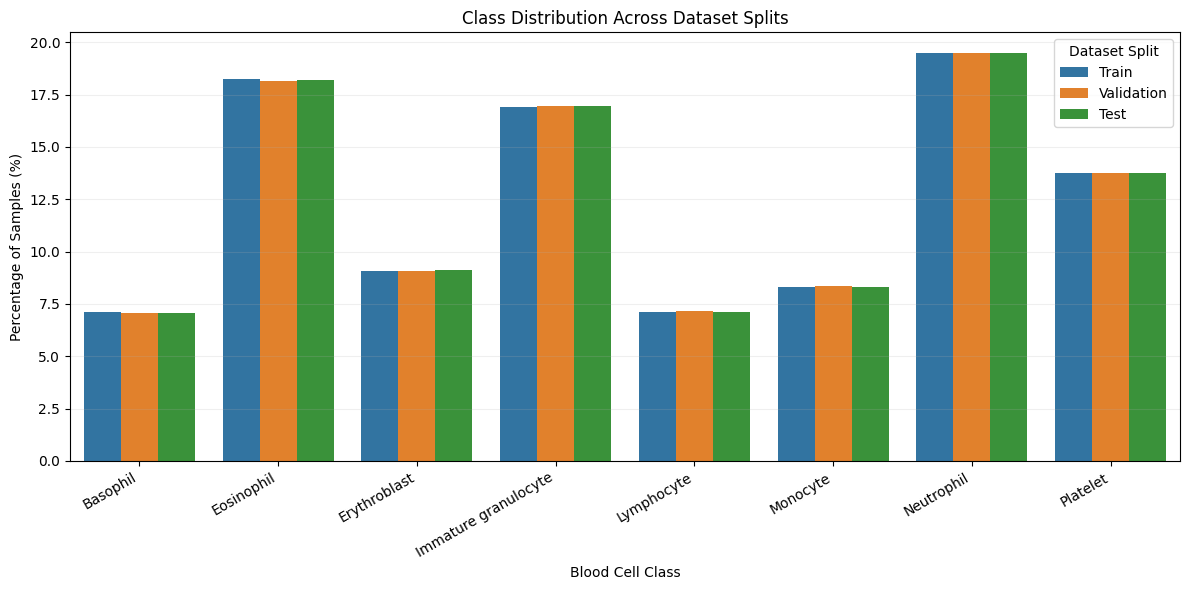

Class distribution chart saved successfully.


In [19]:
# Create shorter display labels for better readability
short_class_names = [
    "Basophil",
    "Eosinophil",
    "Erythroblast",
    "Immature granulocyte",
    "Lymphocyte",
    "Monocyte",
    "Neutrophil",
    "Platelet"
]

# Create a copy for visualisation only
plot_data = class_distribution_df.copy()

# Map original class names to shorter display names
class_name_mapping = dict(zip(class_names, short_class_names))

plot_data["Class"] = plot_data["Class"].map(class_name_mapping)

# Ensure the figure directory exists
os.makedirs("./figures", exist_ok=True)

# Create the grouped bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    data=plot_data,
    x="Class",
    y="Percentage",
    hue="Split"
)

plt.title("Class Distribution Across Dataset Splits")
plt.xlabel("Blood Cell Class")
plt.ylabel("Percentage of Samples (%)")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Dataset Split")
plt.grid(axis="y", alpha=0.2)

plt.tight_layout()

# Save the figure
plt.savefig(
    "./figures/class_distribution_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Class distribution chart saved successfully.")


## 3.7 Visualisation of Sample Images

Visual inspection helps us understand the appearance and variation of the blood cell images before model training.

We display representative samples from all eight classes using images from the cleaned training set.

This allows us to examine visual differences between blood cell categories, including their shape, colour, and structural characteristics.

The selected images are displayed with their corresponding class labels. The original dataset images remain unchanged.

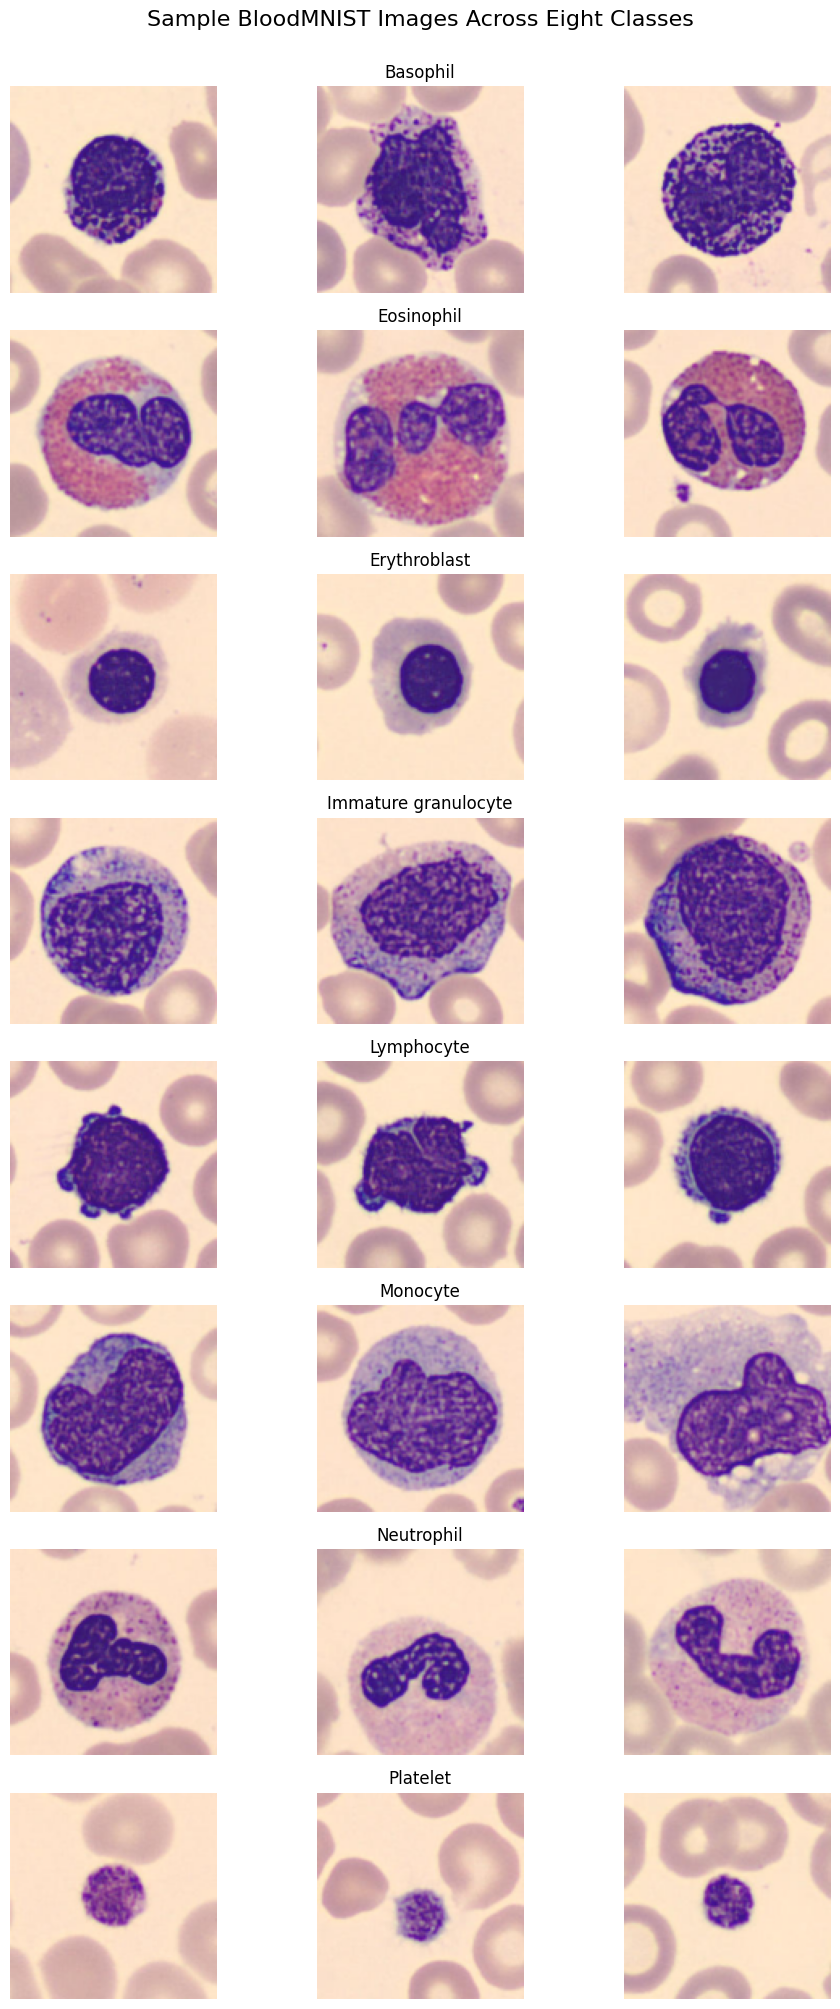

Sample image visualisation saved successfully.


In [20]:
# Define the number of sample images to display per class
SAMPLES_PER_CLASS = 3

# Shorter class names for clearer figure titles
display_class_names = [
    "Basophil",
    "Eosinophil",
    "Erythroblast",
    "Immature granulocyte",
    "Lymphocyte",
    "Monocyte",
    "Neutrophil",
    "Platelet"
]

# Create a reproducible random number generator
rng = np.random.default_rng(SEED)

# Flatten cleaned training labels
train_labels_flat = y_train_clean.flatten()

# Create the figure with 8 rows and 3 columns
fig, axes = plt.subplots(
    nrows=len(class_names),
    ncols=SAMPLES_PER_CLASS,
    figsize=(10, 20)
)

# Display randomly selected images from each class
for class_id, class_name in enumerate(display_class_names):

    # Find indices of images belonging to this class
    class_indices = np.where(
        train_labels_flat == class_id
    )[0]

    # Randomly select images without replacement
    selected_indices = rng.choice(
        class_indices,
        size=min(SAMPLES_PER_CLASS, len(class_indices)),
        replace=False
    )

    # Display selected images
    for column, image_index in enumerate(selected_indices):

        axes[class_id, column].imshow(
            X_train_clean[image_index]
        )

        axes[class_id, column].set_title(
            class_name if column == 1 else ""
        )

        axes[class_id, column].axis("off")

# Add an overall figure title
fig.suptitle(
    "Sample BloodMNIST Images Across Eight Classes",
    fontsize=16,
    y=1.002
)

plt.tight_layout()

# Ensure the figure directory exists
os.makedirs("./figures", exist_ok=True)

# Save the visualisation
plt.savefig(
    "./figures/bloodmnist_sample_images.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Sample image visualisation saved successfully.")


## 3.8 Dataset Exploration Summary

The initial exploration of BloodMNIST confirmed that the original dataset contains 17,092 RGB images distributed across eight blood cell categories.

The downloaded 128 × 128 dataset was successfully loaded, and the official training, validation, and testing splits were verified.

The image integrity checks confirmed consistent image dimensions, matching image-label counts, and no missing or infinite pixel values.

The duplicate audit identified 17 exact duplicate groups, including duplicate images occurring within and across the original dataset splits. One duplicate group contained conflicting class labels. Following a deterministic retention policy, duplicate records were removed, resulting in a cleaned dataset containing 17,075 images: 11,951 training images, 1,709 validation images, and 3,415 testing images.

Class distribution analysis revealed differences in the number of samples across categories, with neutrophils being the most represented class, while basophils and lymphocytes had comparatively lower representation in the training set. The class proportions were similar across the cleaned training, validation, and testing sets.

Visual inspection of representative images from the cleaned training set demonstrated variations in cell morphology, colour, and structure across the eight categories.

These observations provide an understanding of the dataset's characteristics and quality and establish the basis for the preprocessing and model development stages.

### 3.9 Final Verification of the Cleaned Dataset

Before beginning image preprocessing, the cleaned training, validation, and testing sets are verified to ensure that duplicate removal was successful.

The verification checks the number of images and labels in each split, image dimensions, class coverage, and the absence of exact duplicate images within and across the cleaned splits.

This final check ensures that all subsequent preprocessing and model development stages use the same cleaned dataset.

In [21]:
# ============================================================
# 3.9 FINAL VERIFICATION OF THE CLEANED DATASET
# ============================================================

import hashlib

# Define cleaned splits
cleaned_splits = {
    "Train": (X_train_clean, y_train_clean),
    "Validation": (X_val_clean, y_val_clean),
    "Test": (X_test_clean, y_test_clean)
}

expected_counts = {
    "Train": 11951,
    "Validation": 1709,
    "Test": 3415
}

print("FINAL CLEANED DATASET VERIFICATION")
print("=" * 60)

all_hashes = {}
num_classes = len(class_names)

for split_name, (images, labels) in cleaned_splits.items():

    labels_flat = labels.reshape(-1)

    # Verify image and label counts
    assert len(images) == len(labels_flat)
    assert len(images) == expected_counts[split_name]

    # Verify image dimensions
    assert images.ndim == 4
    assert images.shape[1:] == (128, 128, 3)

    # Verify class coverage
    assert set(np.unique(labels_flat)) == set(range(num_classes))

    print(f"\n{split_name}:")
    print("Images:", len(images))
    print("Labels:", len(labels_flat))
    print("Image shape:", images.shape)
    print("Classes represented:", len(np.unique(labels_flat)))

    # Calculate image hashes to check exact duplicates
    for index, image_array in enumerate(images):

        image_hash = hashlib.sha256(
            image_array.tobytes()
        ).hexdigest()

        assert image_hash not in all_hashes, (
            f"Duplicate found in {split_name} at index {index}. "
            f"Previously found in {all_hashes.get(image_hash)}"
        )

        all_hashes[image_hash] = (split_name, index)

# Verify total number of images
total_images = sum(
    len(images) for images, labels in cleaned_splits.values()
)

assert total_images == 17075
assert len(all_hashes) == total_images

print("\n" + "=" * 60)
print("Total cleaned images:", total_images)
print("Unique image hashes:", len(all_hashes))
print("Exact duplicates remaining: 0")

print("\nAll cleaned dataset verification checks passed.")

FINAL CLEANED DATASET VERIFICATION

Train:
Images: 11951
Labels: 11951
Image shape: (11951, 128, 128, 3)
Classes represented: 8

Validation:
Images: 1709
Labels: 1709
Image shape: (1709, 128, 128, 3)
Classes represented: 8

Test:
Images: 3415
Labels: 3415
Image shape: (3415, 128, 128, 3)
Classes represented: 8

Total cleaned images: 17075
Unique image hashes: 17075
Exact duplicates remaining: 0

All cleaned dataset verification checks passed.


### 4.1 Defining Image Transformations

Image preprocessing is an important step in preparing the BloodMNIST dataset for deep learning. The original images have dimensions of 128 × 128 pixels and contain RGB colour information.

In this project, the images are prepared for the pretrained ResNet-18 architecture using the following transformations:

1. **Resizing:** Images are resized to 224 × 224 pixels to match the standard input size commonly used with ImageNet-pretrained ResNet-18.
2. **Data augmentation:** Random horizontal flipping, vertical flipping and small rotations are applied only to training images. These transformations introduce variations and may improve the model's ability to generalise.
3. **Conversion to tensors:** Images are converted into PyTorch tensors with pixel values scaled to the range [0, 1].
4. **Normalization:** RGB channels are normalized using the ImageNet mean and standard deviation because ResNet-18 is pretrained on ImageNet.

Separate transformation pipelines are defined for training and evaluation. Validation and test images do not undergo random augmentation, ensuring consistent evaluation.

The cleaned BloodMNIST training, validation and testing splits created in Section 3.5 are used throughout the experiments. Duplicate records were removed before preprocessing according to the defined retention policy. The cleaned splits contain 11,951 training images, 1,709 validation images and 3,415 testing images.

In [22]:
# --------------------------------------------------
# 4.1 Defining Image Transformations
# --------------------------------------------------

# ImageNet normalization parameters
# These values correspond to the RGB channels.
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


# Transformations applied to training images
# Random augmentation is used only during training.
train_transform = transforms.Compose([
    transforms.ToPILImage(),                  # Convert NumPy image to PIL format
    transforms.Resize((224, 224)),            # Resize image for ResNet-18
    transforms.RandomHorizontalFlip(p=0.5),   # Random horizontal flip
    transforms.RandomVerticalFlip(p=0.5),     # Random vertical flip
    transforms.RandomRotation(degrees=15),    # Random rotation up to 15 degrees
    transforms.ToTensor(),                    # Convert image to PyTorch tensor
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )                                         # Apply ImageNet normalization
])


# Transformations applied to validation and test images
# No random augmentation is applied during evaluation.
eval_transform = transforms.Compose([
    transforms.ToPILImage(),                  # Convert NumPy image to PIL format
    transforms.Resize((224, 224)),            # Resize image for ResNet-18
    transforms.ToTensor(),                    # Convert image to PyTorch tensor
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )                                         # Apply ImageNet normalization
])


print("Training transformations defined successfully.")
print("Evaluation transformations defined successfully.")

Training transformations defined successfully.
Evaluation transformations defined successfully.


### 4.2 Applying and Verifying Image Preprocessing

The defined transformations are applied to sample images from the cleaned training and validation datasets.

The training transformation includes random data augmentation, while the evaluation transformation applies only resizing, tensor conversion and ImageNet normalization.

The resulting tensor dimensions and pixel value ranges are checked to verify that the preprocessing pipelines work correctly and produce the expected input format for ResNet-18.

In [32]:
# --------------------------------------------------
# 4.2 Applying and Verifying Image Preprocessing
# --------------------------------------------------

# Select one sample image from the cleaned training dataset
sample_train_image = X_train_clean[0]

# Select one sample image from the cleaned validation dataset
sample_val_image = X_val_clean[0]

# Apply the respective transformations
processed_train_image = train_transform(sample_train_image)
processed_val_image = eval_transform(sample_val_image)

# Display preprocessing results
print("Training image:")
print("Tensor shape:", processed_train_image.shape)
print("Minimum pixel value:", processed_train_image.min().item())
print("Maximum pixel value:", processed_train_image.max().item())

print("\nValidation image:")
print("Tensor shape:", processed_val_image.shape)
print("Minimum pixel value:", processed_val_image.min().item())
print("Maximum pixel value:", processed_val_image.max().item())

# Verify the expected tensor dimensions
assert processed_train_image.shape == (3, 224, 224)
assert processed_val_image.shape == (3, 224, 224)

print("\nImage preprocessing verified successfully.")


Training image:
Tensor shape: torch.Size([3, 224, 224])
Minimum pixel value: -2.1179039478302
Maximum pixel value: 2.248908281326294

Validation image:
Tensor shape: torch.Size([3, 224, 224])
Minimum pixel value: -1.755602240562439
Maximum pixel value: 2.248908281326294

Image preprocessing verified successfully.


### 4.3 Preparing Image Labels

The BloodMNIST labels are stored as two-dimensional arrays. They are converted into one-dimensional arrays and cast to the `int64` data type to make them compatible with PyTorch classification workflows.

The labels from the cleaned training, validation and test datasets are used to ensure that each image remains correctly aligned with its corresponding class label. The prepared labels are then checked for their dimensions, dataset sizes and class values.

In [23]:
# --------------------------------------------------
# 4.3 Preparing Image Labels
# --------------------------------------------------

# Flatten labels from the cleaned datasets
# Original label arrays are preserved.
y_train_final = y_train_clean.reshape(-1).astype(np.int64)
y_val_final = y_val_clean.reshape(-1).astype(np.int64)
y_test_final = y_test_clean.reshape(-1).astype(np.int64)

# Display dataset and label information
print("Training labels shape:", y_train_final.shape)
print("Validation labels shape:", y_val_final.shape)
print("Test labels shape:", y_test_final.shape)

print("\nNumber of training classes:", len(np.unique(y_train_final)))
print("Unique training labels:", np.unique(y_train_final))

# Verify image-label alignment
assert len(X_train_clean) == len(y_train_final)
assert len(X_val_clean) == len(y_val_final)
assert len(X_test_clean) == len(y_test_final)

# Verify label dimensions
assert y_train_final.ndim == 1
assert y_val_final.ndim == 1
assert y_test_final.ndim == 1

# Verify label data types
assert y_train_final.dtype == np.int64
assert y_val_final.dtype == np.int64
assert y_test_final.dtype == np.int64

# Verify that all expected classes are represented
expected_classes = np.arange(len(class_names))

assert np.array_equal(np.unique(y_train_final), expected_classes)
assert np.array_equal(np.unique(y_val_final), expected_classes)
assert np.array_equal(np.unique(y_test_final), expected_classes)

print("\nImage-label alignment verified successfully.")
print("Label preparation completed successfully.")


Training labels shape: (11951,)
Validation labels shape: (1709,)
Test labels shape: (3415,)

Number of training classes: 8
Unique training labels: [0 1 2 3 4 5 6 7]

Image-label alignment verified successfully.
Label preparation completed successfully.


### 4.4 Creating PyTorch Dataset Objects

Custom PyTorch Dataset objects are created for the cleaned training, validation and test sets. Each dataset returns a preprocessed image and its corresponding class label.

The training dataset uses the training transformation, which includes data augmentation. The validation and test datasets use the evaluation transformation without random augmentation.

The dataset sizes and sample output are inspected to verify that the cleaned images and labels are correctly loaded and compatible with the ResNet-18 model.

In [24]:
# --------------------------------------------------
# 4.4 Creating PyTorch Dataset Objects
# --------------------------------------------------

from torch.utils.data import Dataset, DataLoader


class BloodMNISTDataset(Dataset):
    """Custom PyTorch dataset for BloodMNIST images."""

    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        # Return the total number of images
        return len(self.images)

    def __getitem__(self, index):
        # Retrieve an image and its corresponding label
        image = self.images[index]
        label = self.labels[index]

        # Apply image transformations when specified
        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(label, dtype=torch.long)


# Create datasets using the cleaned splits
train_dataset = BloodMNISTDataset(
    X_train_clean, y_train_final, transform=train_transform
)

val_dataset = BloodMNISTDataset(
    X_val_clean, y_val_final, transform=eval_transform
)

test_dataset = BloodMNISTDataset(
    X_test_clean, y_test_final, transform=eval_transform
)


# Verify dataset sizes
print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))

# Verify expected dataset sizes
assert len(train_dataset) == 11951
assert len(val_dataset) == 1709
assert len(test_dataset) == 3415

# Inspect one sample from the training dataset
sample_image, sample_label = train_dataset[0]

print("\nSample image shape:", sample_image.shape)
print("Sample label:", sample_label.item())
print("Sample label dtype:", sample_label.dtype)

# Verify sample properties
assert sample_image.shape == (3, 224, 224)
assert isinstance(sample_label, torch.Tensor)
assert sample_label.dtype == torch.long
assert 0 <= sample_label.item() < len(class_names)

print("\nPyTorch Dataset objects created and verified successfully.")


Training dataset: 11951
Validation dataset: 1709
Test dataset: 3415

Sample image shape: torch.Size([3, 224, 224])
Sample label: 7
Sample label dtype: torch.int64

PyTorch Dataset objects created and verified successfully.


### 4.5 Creating DataLoaders

PyTorch DataLoaders will organize the datasets into batches for efficient training and evaluation. Shuffling will be enabled only for the training dataset.

In [25]:
# --------------------------------------------------
# 4.5 Creating DataLoaders
# --------------------------------------------------

# Define batch size
BATCH_SIZE = 64

# Use a single process to avoid shared memory issues
NUM_WORKERS = 0

# Create training DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

# Create validation DataLoader
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

# Create test DataLoader
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))
print("Batch size:", BATCH_SIZE)
print("Number of workers:", NUM_WORKERS)

Training batches: 187
Validation batches: 27
Test batches: 54
Batch size: 64
Number of workers: 0


### 4.6 Verifying DataLoader Batches

Sample batches from the training, validation and test DataLoaders are inspected to verify image dimensions, label dimensions and data types.

The checks confirm that images have the expected ResNet-18 input dimensions, labels use the appropriate integer format and all class labels fall within the valid eight-class range.

The batch tensors are also checked for compatibility with the selected computing device before model development.

In [26]:
# --------------------------------------------------
# 4.6 Verifying DataLoader Batches
# --------------------------------------------------

# Retrieve one batch from each DataLoader
train_images, train_labels = next(iter(train_loader))
val_images, val_labels = next(iter(val_loader))
test_images, test_labels = next(iter(test_loader))


# Function to verify batch properties
def verify_batch(images, labels, split_name):

    print(f"\n{split_name} batch:")
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Image data type:", images.dtype)
    print("Label data type:", labels.dtype)

    # Verify image dimensions
    assert images.ndim == 4
    assert images.shape[1:] == (3, 224, 224)

    # Verify image-label alignment
    assert images.shape[0] == labels.shape[0]

    # Verify data types
    assert images.dtype == torch.float32
    assert labels.dtype == torch.long

    # Verify label range
    assert torch.all(labels >= 0)
    assert torch.all(labels < len(class_names))

    print(f"{split_name} batch verification passed.")


# Verify all three DataLoaders
verify_batch(train_images, train_labels, "Training")
verify_batch(val_images, val_labels, "Validation")
verify_batch(test_images, test_labels, "Test")


# Display computing device
print("\nCurrent device:", DEVICE)

# Verify device availability
if DEVICE.type == "cuda":
    assert torch.cuda.is_available()
elif DEVICE.type == "mps":
    assert torch.backends.mps.is_available()
elif DEVICE.type == "cpu":
    assert True

print("\nAll DataLoader batch verification checks passed.")



Training batch:
Image batch shape: torch.Size([64, 3, 224, 224])
Label batch shape: torch.Size([64])
Image data type: torch.float32
Label data type: torch.int64
Training batch verification passed.

Validation batch:
Image batch shape: torch.Size([64, 3, 224, 224])
Label batch shape: torch.Size([64])
Image data type: torch.float32
Label data type: torch.int64
Validation batch verification passed.

Test batch:
Image batch shape: torch.Size([64, 3, 224, 224])
Label batch shape: torch.Size([64])
Image data type: torch.float32
Label data type: torch.int64
Test batch verification passed.

Current device: cuda

All DataLoader batch verification checks passed.


# 5. ResNet-18 Model Development

This section develops ResNet-18 models for multiclass blood cell classification using ImageNet-pretrained weights. Two transfer learning approaches are investigated: a frozen pretrained backbone and a fine-tuned pretrained backbone.

### 5.1 Introduction to ResNet-18 Architecture

ResNet-18 is a convolutional neural network (CNN) that uses residual connections to improve information and gradient flow during training. It consists of convolutional layers, residual blocks and a final fully connected classification layer.

In this project, ResNet-18 is initialized with ImageNet-pretrained weights. Its learned visual features are adapted to classify the eight BloodMNIST blood cell categories.

Two approaches are compared:

- **Frozen backbone:** The pretrained feature extraction layers remain unchanged, while only the final classification layer is trained.
- **Fine-tuned backbone:** The pretrained layers and the new classification layer are trained on the BloodMNIST dataset.

### 5.2 Loading ImageNet-Pretrained ResNet-18

The ResNet-18 architecture is loaded with weights pretrained on the ImageNet dataset. These weights provide previously learned visual features that can be transferred to the BloodMNIST classification task.

The pretrained model is moved to the selected computing device (GPU or CPU) for subsequent training. Its original classification layer is inspected before being replaced with a new layer containing eight output classes.

In [27]:
# --------------------------------------------------
# 5.2 Loading ImageNet-Pretrained ResNet-18
# --------------------------------------------------

# Load ResNet-18 with ImageNet-pretrained weights
weights = models.ResNet18_Weights.DEFAULT

pretrained_model = models.resnet18(weights=weights)

# Move the model to the selected device
pretrained_model = pretrained_model.to(DEVICE)

# Display the model architecture
print(pretrained_model)

# Verify the model's final classification layer
print("\nOriginal classification layer:")
print(pretrained_model.fc)

# Display the number of output classes in ImageNet
print("\nOriginal output features:", pretrained_model.fc.out_features)

# Verify model initialization
assert pretrained_model.fc.out_features == 1000
assert next(pretrained_model.parameters()).device.type == DEVICE.type

print("\nPretrained ResNet-18 loaded successfully.")
print("Model device:", next(pretrained_model.parameters()).device)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /home/jovyan/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 113MB/s]

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

### 5.3 Understanding the Pretrained Feature Extractor

The pretrained ResNet-18 contains four main residual stages: `layer1`, `layer2`, `layer3` and `layer4`. These layers progressively extract visual features, from basic patterns to more complex structures.

The final feature representation contains 512 features, which are passed to a fully connected classification layer. In this project, these features will be used by a new classification layer designed to predict the eight BloodMNIST classes

In [28]:
# --------------------------------------------------
# 5.3 Understanding the Pretrained Feature Extractor
# --------------------------------------------------

# Inspect the main feature extraction layers of ResNet-18
print("Feature extraction layers:")

for name, layer in pretrained_model.named_children():
    if name in ["layer1", "layer2", "layer3", "layer4"]:
        print(f"{name}: {layer}")

# Display the number of input features for the final classifier
print("\nFeatures extracted before classification:",
      pretrained_model.fc.in_features)

# Verify the feature extractor output dimension
assert pretrained_model.fc.in_features == 512

print("\nResNet-18 feature extractor verified successfully.")


Feature extraction layers:
layer1: Sequential(
  (0): BasicBlock(
    (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (1): BasicBlock(
    (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
)
layer2: Sequential(
  (0): BasicBlock(
    (conv1): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 

### 5.4 Replacing the Final Classification Layer

The original ResNet-18 classification layer produces 1,000 outputs for ImageNet categories. Since BloodMNIST contains eight blood cell classes, the original fully connected layer is replaced with a new layer containing eight output neurons.

The new classification layer receives 512 input features extracted by the pretrained backbone and produces predictions for the eight BloodMNIST classes.

The updated model is moved to the selected computing device for subsequent training.

In [29]:
# --------------------------------------------------
# 5.4 Replacing the Final Classification Layer
# --------------------------------------------------

# Define the number of BloodMNIST classes
NUM_CLASSES = len(class_names)

# Replace the original ImageNet classifier
pretrained_model.fc = nn.Linear(
    pretrained_model.fc.in_features,
    NUM_CLASSES
)

# Move the updated model to the selected device
pretrained_model = pretrained_model.to(DEVICE)

# Verify the new classification layer
print("Updated classification layer:")
print(pretrained_model.fc)

print("\nNumber of output classes:",
      pretrained_model.fc.out_features)

# Verify classifier dimensions
assert pretrained_model.fc.in_features == 512
assert pretrained_model.fc.out_features == NUM_CLASSES
assert NUM_CLASSES == 8

# Verify model device
assert next(pretrained_model.parameters()).device.type == DEVICE.type

print("\nEight-class ResNet-18 classifier verified successfully.")
print("Model device:", next(pretrained_model.parameters()).device)


Updated classification layer:
Linear(in_features=512, out_features=8, bias=True)

Number of output classes: 8

Eight-class ResNet-18 classifier verified successfully.
Model device: cuda:0


### 5.5 Configuring the Frozen Backbone

In the frozen backbone approach, all pretrained ResNet-18 feature extraction parameters are frozen by disabling gradient updates. Only the newly added fully connected classification layer remains trainable.

This allows the model to use ImageNet-learned features while learning a new classifier for the eight BloodMNIST classes.

A separate copy of the initialized model is created for the frozen experiment to ensure that the frozen and fine-tuned approaches start independently. The pretrained backbone's Batch Normalization statistics are also kept unchanged during training.

In [30]:
# --------------------------------------------------
# 5.5 Configuring the Frozen Backbone
# --------------------------------------------------

import copy

# Create an independent copy for the frozen experiment
frozen_model = copy.deepcopy(pretrained_model)

# Freeze all parameters in the pretrained backbone
for name, param in frozen_model.named_parameters():
    if not name.startswith("fc."):
        param.requires_grad = False

# Enable training only for the new classification layer
for param in frozen_model.fc.parameters():
    param.requires_grad = True

# Move the model to the selected device
frozen_model = frozen_model.to(DEVICE)

# Count trainable and total parameters
total_parameters = sum(
    param.numel() for param in frozen_model.parameters()
)

trainable_parameters = sum(
    param.numel()
    for param in frozen_model.parameters()
    if param.requires_grad
)

print("Total parameters:", total_parameters)
print("Trainable parameters:", trainable_parameters)
print("Frozen parameters:", total_parameters - trainable_parameters)

# Display trainable parameters
print("\nTrainable parameters:")
for name, param in frozen_model.named_parameters():
    if param.requires_grad:
        print(name)

# Verify that only the classification layer is trainable
assert all(
    param.requires_grad == name.startswith("fc.")
    for name, param in frozen_model.named_parameters()
)

assert frozen_model.fc.out_features == NUM_CLASSES

print("\nFrozen backbone configuration verified successfully.")


Total parameters: 11180616
Trainable parameters: 4104
Frozen parameters: 11176512

Trainable parameters:
fc.weight
fc.bias

Frozen backbone configuration verified successfully.


### 5.6 Configuring the Fine-Tuned Backbone

In the fine-tuning approach, all pretrained ResNet-18 layers, including the new fully connected classification layer, are made trainable.

This allows the model to adjust its pretrained visual features to the BloodMNIST dataset during training. A separate model is initialized with ImageNet-pretrained weights to ensure that the fine-tuning experiment is independent of the frozen backbone experiment

In [31]:
# --------------------------------------------------
# 5.6 Configuring the Fine-Tuned Backbone
# --------------------------------------------------

# Load a separate ResNet-18 model with ImageNet-pretrained weights
finetuned_model = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

# Replace the original classifier with an 8-class output layer
finetuned_model.fc = nn.Linear(
    finetuned_model.fc.in_features,
    NUM_CLASSES
)

# Move the model to the selected device
finetuned_model = finetuned_model.to(DEVICE)

# Enable training for all model parameters
for param in finetuned_model.parameters():
    param.requires_grad = True

# Count trainable and total parameters
total_parameters = sum(
    param.numel() for param in finetuned_model.parameters()
)

trainable_parameters = sum(
    param.numel()
    for param in finetuned_model.parameters()
    if param.requires_grad
)

print("Total parameters:", total_parameters)
print("Trainable parameters:", trainable_parameters)
print("Frozen parameters:", total_parameters - trainable_parameters)

# Verify fine-tuning configuration
assert trainable_parameters == total_parameters
assert finetuned_model.fc.in_features == 512
assert finetuned_model.fc.out_features == NUM_CLASSES
assert next(finetuned_model.parameters()).device.type == DEVICE.type

print("\nFine-tuned backbone configuration verified successfully.")
print("Model device:", next(finetuned_model.parameters()).device)


Total parameters: 11180616
Trainable parameters: 11180616
Frozen parameters: 0

Fine-tuned backbone configuration verified successfully.
Model device: cuda:0


### 5.7 Defining Loss Function and Optimisers

Cross-Entropy Loss is used because the task involves multiclass classification with integer class labels.

The AdamW optimiser is selected for model training. It applies adaptive learning rates and decoupled weight decay to help regularise the model.

Separate optimisers are configured for the two experiments:

- **Frozen model:** Updates only the final eight-class classification layer, using a learning rate of 0.001.
- **Fine-tuned model:** Updates all trainable model parameters, using a learning rate of 0.0001.

A weight decay of 0.0001 is applied to both optimisers.

In [32]:
# --------------------------------------------------
# 5.7 Defining Loss Function and Optimisers
# --------------------------------------------------

# Define the loss function
criterion = nn.CrossEntropyLoss()

# Define the optimiser for the frozen backbone
# Only the new classification layer is updated.
frozen_optimizer = torch.optim.AdamW(
    frozen_model.fc.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

# Define the optimiser for the fine-tuned backbone
# All trainable model parameters are updated.
finetuned_optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, finetuned_model.parameters()),
    lr=0.0001,
    weight_decay=0.0001
)

# Verify optimiser configurations
print("Loss function:", criterion)

print("\nFrozen model optimiser:")
print(frozen_optimizer)

print("\nFine-tuned model optimiser:")
print(finetuned_optimizer)

# Verify optimiser parameter connections
frozen_optimizer_params = {
    id(p)
    for group in frozen_optimizer.param_groups
    for p in group["params"]
}

finetuned_optimizer_params = {
    id(p)
    for group in finetuned_optimizer.param_groups
    for p in group["params"]
}

expected_frozen_params = {
    id(p) for p in frozen_model.fc.parameters()
}

expected_finetuned_params = {
    id(p)
    for p in finetuned_model.parameters()
    if p.requires_grad
}

assert frozen_optimizer_params == expected_frozen_params
assert finetuned_optimizer_params == expected_finetuned_params

assert frozen_optimizer.defaults["lr"] == 0.001
assert finetuned_optimizer.defaults["lr"] == 0.0001

print("\nOptimizer configurations verified successfully.")


Loss function: CrossEntropyLoss()

Frozen model optimiser:
AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.0001
)

Fine-tuned model optimiser:
AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0.0001
)

Optimizer configurations verified successfully.


### 5.8 Defining Training Configuration and Reproducibility

The training configuration is established to ensure consistent and reproducible experiments across the frozen and fine-tuned ResNet-18 models.

Both approaches use a batch size of 64 and are trained for 10 epochs. Three random seeds (42, 43 and 44) are used to assess the consistency of model performance.

The frozen model uses a learning rate of 0.001, while the fine-tuned model uses a learning rate of 0.0001. Both models use the AdamW optimiser with a weight decay of 0.0001 and Cross-Entropy Loss.

Random seeds are controlled across Python, NumPy and PyTorch to improve reproducibility. The best model checkpoint for each run is selected using validation accuracy. The test dataset is reserved for final evaluation.

In [33]:
# --------------------------------------------------
# 5.8 Defining Training Configuration and Reproducibility
# --------------------------------------------------

import random
import numpy as np
import torch
import os

# Training configuration
NUM_EPOCHS = 10
BATCH_SIZE = 64
SEEDS = [42, 43, 44]

FROZEN_LR = 0.001
FINETUNED_LR = 0.0001
WEIGHT_DECAY = 0.0001

# Function to set random seeds
def set_seed(seed):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    # Enable deterministic operations where possible
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


# Display training configuration
print("Training configuration")
print("----------------------")
print("Epochs:", NUM_EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Random seeds:", SEEDS)

print("\nFrozen model learning rate:", FROZEN_LR)
print("Fine-tuned model learning rate:", FINETUNED_LR)
print("Weight decay:", WEIGHT_DECAY)

print("\nComputing device:", DEVICE)

# Verify configuration
assert NUM_EPOCHS == 10
assert BATCH_SIZE == 64
assert SEEDS == [42, 43, 44]
assert FROZEN_LR == 0.001
assert FINETUNED_LR == 0.0001
assert WEIGHT_DECAY == 0.0001

print("\nTraining configuration verified successfully.")


Training configuration
----------------------
Epochs: 10
Batch size: 64
Random seeds: [42, 43, 44]

Frozen model learning rate: 0.001
Fine-tuned model learning rate: 0.0001
Weight decay: 0.0001

Computing device: cuda

Training configuration verified successfully.


# 6. Model Training and Experiments

This section describes the training and evaluation experiments conducted using the frozen and fine-tuned ResNet-18 models on the BloodMNIST dataset.

Both approaches use the same cleaned training and validation splits to ensure a consistent comparison. The frozen approach trains only the final classification layer while keeping the pretrained ResNet-18 backbone fixed. The fine-tuned approach updates all model parameters, allowing the pretrained network to adapt to the BloodMNIST images.

To evaluate the consistency and reproducibility of the experiments, both approaches are trained using three random seeds: 42, 43, and 44. Model checkpoints are selected based on validation accuracy, while the cleaned test set is reserved for final performance evaluation.
### 6.1 Defining Experimental Settings and Helper Functions

The experimental settings were established to ensure a consistent and reproducible comparison between the frozen and fine-tuned ResNet-18 models.

Both experiments use a batch size of 64 and a maximum of 10 training epochs. To assess the consistency of the results, each experiment is conducted using three random seeds: 42, 43, and 44.

The cleaned training split is used to train the models, while the cleaned validation split is used to monitor performance and select the best model checkpoint based on validation accuracy. The cleaned test split is reserved exclusively for final evaluation to avoid data leakage.

The experiments use the same cleaned dataset splits, consisting of 11,951 training images, 1,709 validation images, and 3,415 test images.

This section also defines reusable training and evaluation functions. These functions are shared by both experiments to maintain a consistent training and evaluation procedure.

In [34]:
# --------------------------------------------------
# 6.1 Defining Experimental Settings and Helper Functions
# --------------------------------------------------

# Reuse the experimental settings defined in Section 5.8
RANDOM_SEEDS = SEEDS

# Define directory for saving model checkpoints
CHECKPOINT_DIR = "results/checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)


# --------------------------------------------------
# Display and verify experimental settings
# --------------------------------------------------

print("Experimental Settings")
print("---------------------")
print("Batch size:", BATCH_SIZE)
print("Maximum epochs:", NUM_EPOCHS)
print("Random seeds:", RANDOM_SEEDS)
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Checkpoint directory:", CHECKPOINT_DIR)
print("Computing device:", DEVICE)

# Verify experimental settings
assert RANDOM_SEEDS == [42, 43, 44]
assert BATCH_SIZE == 64
assert NUM_EPOCHS == 10
assert len(train_dataset) == 11951
assert len(val_dataset) == 1709
assert len(test_dataset) == 3415

print("\nExperimental settings verified successfully.")


# --------------------------------------------------
# Define training function
# --------------------------------------------------

def train_one_epoch(
    model,
    data_loader,
    criterion,
    optimizer,
    device,
    frozen_backbone=False
):

    if frozen_backbone:
        # Keep pretrained backbone and BatchNorm layers frozen
        model.eval()
        model.fc.train()
    else:
        model.train()

    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    for images, labels in data_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct_predictions += (
            predictions == labels
        ).sum().item()

        total_samples += labels.size(0)

    epoch_loss = running_loss / total_samples
    epoch_accuracy = correct_predictions / total_samples

    return epoch_loss, epoch_accuracy


# --------------------------------------------------
# Define evaluation function
# --------------------------------------------------

def evaluate_model(
    model,
    data_loader,
    criterion,
    device
):

    model.eval()

    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    with torch.no_grad():

        for images, labels in data_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            correct_predictions += (
                predictions == labels
            ).sum().item()

            total_samples += labels.size(0)

    epoch_loss = running_loss / total_samples
    epoch_accuracy = correct_predictions / total_samples

    return epoch_loss, epoch_accuracy


# --------------------------------------------------
# Final verification
# --------------------------------------------------

assert callable(train_one_epoch)
assert callable(evaluate_model)

print("\nTraining and evaluation functions defined successfully.")

Experimental Settings
---------------------
Batch size: 64
Maximum epochs: 10
Random seeds: [42, 43, 44]
Training samples: 11951
Validation samples: 1709
Test samples: 3415
Training batches: 187
Validation batches: 27
Checkpoint directory: results/checkpoints
Computing device: cuda

Experimental settings verified successfully.

Training and evaluation functions defined successfully.


### 6.2 Experiment 1 – Frozen Pretrained ResNet-18

In this experiment, an ImageNet-pretrained ResNet-18 model is used as a feature extractor for BloodMNIST classification. All feature extraction layers are frozen, and only the final fully connected classification layer is trained to predict the eight blood cell classes.

The experiment is repeated using three random seeds (42, 43, and 44) to assess the consistency of the results. During each run, training loss, training accuracy, validation loss, and validation accuracy are monitored after every epoch.

The checkpoint with the highest validation accuracy is saved separately for each seed. The validation set is used for model selection, while the test set remains reserved for the final evaluation.

In [35]:
# Experiment 1: Frozen pretrained ResNet-18

import copy

frozen_results = {}

for seed in RANDOM_SEEDS:

    print(f"\nStarting frozen experiment with seed {seed}")

    # Set random seeds for reproducibility
    set_seed(seed)

    # Load a fresh ImageNet-pretrained ResNet-18
    model = models.resnet18(
        weights=models.ResNet18_Weights.DEFAULT
    )

    # Replace the classifier with an 8-class output layer
    model.fc = nn.Linear(
        model.fc.in_features,
        NUM_CLASSES
    )

    model = model.to(DEVICE)

    # Freeze all model parameters
    for param in model.parameters():
        param.requires_grad = False

    # Enable training only for the final classifier
    for param in model.fc.parameters():
        param.requires_grad = True

    # Verify that only the classifier is trainable
    assert all(
        not param.requires_grad
        for name, param in model.named_parameters()
        if not name.startswith("fc.")
    )

    assert all(
        param.requires_grad
        for param in model.fc.parameters()
    )

    # Define loss function and optimiser
    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.AdamW(
        model.fc.parameters(),
        lr=FROZEN_LR,
        weight_decay=WEIGHT_DECAY
    )

    # Store training history
    history = {
        "train_loss": [],
        "train_accuracy": [],
        "val_loss": [],
        "val_accuracy": []
    }

    best_val_accuracy = -1.0
    best_model_state = None

    # Train the model
    for epoch in range(NUM_EPOCHS):

        train_loss, train_accuracy = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
            DEVICE,
            frozen_backbone=True
        )

        val_loss, val_accuracy = evaluate_model(
            model,
            val_loader,
            criterion,
            DEVICE
        )

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)

        print(
            f"Seed {seed} | Epoch {epoch + 1}/{NUM_EPOCHS} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Accuracy: {train_accuracy:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Accuracy: {val_accuracy:.4f}"
        )

        # Select the best checkpoint using validation accuracy
        if val_accuracy > best_val_accuracy:

            best_val_accuracy = val_accuracy

            best_model_state = copy.deepcopy(
                model.state_dict()
            )

    # Verify that a checkpoint was selected
    assert best_model_state is not None

    # Save the best checkpoint for this seed
    checkpoint_path = os.path.join(
        CHECKPOINT_DIR,
        f"frozen_resnet18_seed_{seed}.pth"
    )

    torch.save(
        {
            "seed": seed,
            "model_state_dict": best_model_state,
            "best_val_accuracy": best_val_accuracy,
            "history": history
        },
        checkpoint_path
    )

    # Store experiment results
    frozen_results[seed] = {
        "history": history,
        "best_val_accuracy": best_val_accuracy,
        "checkpoint": checkpoint_path
    }

    print(
        f"Best validation accuracy for seed {seed}: "
        f"{best_val_accuracy:.4f}"
    )

    print("Checkpoint saved:", checkpoint_path)


print("\nFrozen ResNet-18 experiments completed.")


Starting frozen experiment with seed 42
Seed 42 | Epoch 1/10 | Train Loss: 1.0573 | Train Accuracy: 0.6978 | Val Loss: 0.7640 | Val Accuracy: 0.7443
Seed 42 | Epoch 2/10 | Train Loss: 0.5813 | Train Accuracy: 0.8414 | Val Loss: 0.5715 | Val Accuracy: 0.8116
Seed 42 | Epoch 3/10 | Train Loss: 0.4636 | Train Accuracy: 0.8682 | Val Loss: 0.5021 | Val Accuracy: 0.8321
Seed 42 | Epoch 4/10 | Train Loss: 0.4078 | Train Accuracy: 0.8788 | Val Loss: 0.4548 | Val Accuracy: 0.8461
Seed 42 | Epoch 5/10 | Train Loss: 0.3814 | Train Accuracy: 0.8829 | Val Loss: 0.4362 | Val Accuracy: 0.8514
Seed 42 | Epoch 6/10 | Train Loss: 0.3544 | Train Accuracy: 0.8919 | Val Loss: 0.4094 | Val Accuracy: 0.8602
Seed 42 | Epoch 7/10 | Train Loss: 0.3325 | Train Accuracy: 0.8975 | Val Loss: 0.3828 | Val Accuracy: 0.8637
Seed 42 | Epoch 8/10 | Train Loss: 0.3097 | Train Accuracy: 0.9069 | Val Loss: 0.3558 | Val Accuracy: 0.8800
Seed 42 | Epoch 9/10 | Train Loss: 0.3040 | Train Accuracy: 0.9039 | Val Loss: 0.3390 |

### 6.3 Experiment 2 – Fine-Tuned Pretrained ResNet-18

In this experiment, all layers of the ImageNet-pretrained ResNet-18 model are fine-tuned using the BloodMNIST training dataset. Unlike the frozen approach, all feature extraction layers are allowed to update their weights during training, enabling the model to adapt its learned representations to blood cell images.

The experiment is repeated using three random seeds (42, 43, and 44) to assess the consistency of the results. Training loss, training accuracy, validation loss, and validation accuracy are monitored after every epoch.

The checkpoint with the highest validation accuracy is saved separately for each seed. The validation set is used for model selection, while the cleaned test set remains reserved for the final evaluation.

In [36]:
# --------------------------------------------------
# Experiment 2: Fine-tuned pretrained ResNet-18
# --------------------------------------------------

finetuned_results = {}

for seed in RANDOM_SEEDS:

    print(f"\nStarting fine-tuned experiment with seed {seed}")

    # Set random seeds for reproducibility
    set_seed(seed)

    # Load a fresh ImageNet-pretrained ResNet-18
    model = models.resnet18(
        weights=models.ResNet18_Weights.DEFAULT
    )

    # Replace the original classifier with an 8-class output layer
    model.fc = nn.Linear(
        model.fc.in_features,
        NUM_CLASSES
    )

    model = model.to(DEVICE)

    # Enable training for all model parameters
    for param in model.parameters():
        param.requires_grad = True

    # Verify that all parameters are trainable
    assert all(
        param.requires_grad
        for param in model.parameters()
    )

    # Define loss function and optimiser
    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=FINETUNED_LR,
        weight_decay=WEIGHT_DECAY
    )

    # Store training history
    history = {
        "train_loss": [],
        "train_accuracy": [],
        "val_loss": [],
        "val_accuracy": []
    }

    best_val_accuracy = -1.0
    best_model_state = None

    # Train the model
    for epoch in range(NUM_EPOCHS):

        train_loss, train_accuracy = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
            DEVICE,
            frozen_backbone=False
        )

        val_loss, val_accuracy = evaluate_model(
            model,
            val_loader,
            criterion,
            DEVICE
        )

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)

        print(
            f"Seed {seed} | Epoch {epoch + 1}/{NUM_EPOCHS} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Accuracy: {train_accuracy:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Accuracy: {val_accuracy:.4f}"
        )

        # Save the best model based on validation accuracy
        if val_accuracy > best_val_accuracy:

            best_val_accuracy = val_accuracy

            best_model_state = copy.deepcopy(
                model.state_dict()
            )

    # Verify that a checkpoint was selected
    assert best_model_state is not None

    # Save the best checkpoint for this seed
    checkpoint_path = os.path.join(
        CHECKPOINT_DIR,
        f"finetuned_resnet18_seed_{seed}.pth"
    )

    torch.save(
        {
            "seed": seed,
            "model_state_dict": best_model_state,
            "best_val_accuracy": best_val_accuracy,
            "history": history
        },
        checkpoint_path
    )

    # Store experiment results
    finetuned_results[seed] = {
        "history": history,
        "best_val_accuracy": best_val_accuracy,
        "checkpoint": checkpoint_path
    }

    print(
        f"Best validation accuracy for seed {seed}: "
        f"{best_val_accuracy:.4f}"
    )

    print("Checkpoint saved:", checkpoint_path)


print("\nFine-tuned ResNet-18 experiments completed.")


Starting fine-tuned experiment with seed 42
Seed 42 | Epoch 1/10 | Train Loss: 0.1864 | Train Accuracy: 0.9423 | Val Loss: 0.0584 | Val Accuracy: 0.9783
Seed 42 | Epoch 2/10 | Train Loss: 0.0595 | Train Accuracy: 0.9805 | Val Loss: 0.0366 | Val Accuracy: 0.9871
Seed 42 | Epoch 3/10 | Train Loss: 0.0441 | Train Accuracy: 0.9850 | Val Loss: 0.0646 | Val Accuracy: 0.9789
Seed 42 | Epoch 4/10 | Train Loss: 0.0354 | Train Accuracy: 0.9868 | Val Loss: 0.0335 | Val Accuracy: 0.9883
Seed 42 | Epoch 5/10 | Train Loss: 0.0307 | Train Accuracy: 0.9897 | Val Loss: 0.0309 | Val Accuracy: 0.9906
Seed 42 | Epoch 6/10 | Train Loss: 0.0243 | Train Accuracy: 0.9908 | Val Loss: 0.0287 | Val Accuracy: 0.9906
Seed 42 | Epoch 7/10 | Train Loss: 0.0249 | Train Accuracy: 0.9911 | Val Loss: 0.0429 | Val Accuracy: 0.9830
Seed 42 | Epoch 8/10 | Train Loss: 0.0235 | Train Accuracy: 0.9919 | Val Loss: 0.0282 | Val Accuracy: 0.9912
Seed 42 | Epoch 9/10 | Train Loss: 0.0197 | Train Accuracy: 0.9936 | Val Loss: 0.06

### 6.4 Training Using Multiple Random Seeds

Both frozen and fine-tuned ResNet-18 experiments were conducted using three random seeds (42, 43, and 44) to assess the consistency and reproducibility of the results.

For each experiment, the best validation accuracy from each seed was recorded. The mean and sample standard deviation were calculated across the three runs to compare validation performance and variability between the frozen and fine-tuned approaches.

These validation results provide an overview of model consistency and are used for comparison before the final evaluation on the cleaned test set.

In [37]:
# --------------------------------------------------
# 6.4 Training Using Multiple Random Seeds
# --------------------------------------------------

# Verify that all three seed runs are completed
assert all(seed in frozen_results for seed in RANDOM_SEEDS)
assert all(seed in finetuned_results for seed in RANDOM_SEEDS)

# Extract best validation accuracies
frozen_accuracies = [
    frozen_results[seed]["best_val_accuracy"]
    for seed in RANDOM_SEEDS
]

finetuned_accuracies = [
    finetuned_results[seed]["best_val_accuracy"]
    for seed in RANDOM_SEEDS
]

# Calculate mean and sample standard deviation
frozen_mean = np.mean(frozen_accuracies)
frozen_std = np.std(frozen_accuracies, ddof=1)

finetuned_mean = np.mean(finetuned_accuracies)
finetuned_std = np.std(finetuned_accuracies, ddof=1)

# Calculate improvement in percentage points
improvement = (finetuned_mean - frozen_mean) * 100

# Display comparison
print("MULTI-SEED VALIDATION RESULTS")
print("-" * 50)

print(
    f"Frozen ResNet-18:     {frozen_mean * 100:.2f}% "
    f"+/- {frozen_std * 100:.2f}%"
)

print(
    f"Fine-tuned ResNet-18: {finetuned_mean * 100:.2f}% "
    f"+/- {finetuned_std * 100:.2f}%"
)

print(
    f"\nImprovement: {improvement:.2f} percentage points"
)

print("\nResults calculated successfully.")

MULTI-SEED VALIDATION RESULTS
--------------------------------------------------
Frozen ResNet-18:     88.43% +/- 0.48%
Fine-tuned ResNet-18: 99.20% +/- 0.09%

Improvement: 10.77 percentage points

Results calculated successfully.


### 6.5 Monitoring Training and Validation Performance

Training and validation loss and accuracy were monitored over 10 epochs for each random seed. The performance of both frozen and fine-tuned ResNet-18 models was recorded to observe learning progress and generalisation.

For each run, the checkpoint with the highest validation accuracy was selected and saved. The best validation accuracy and corresponding epoch are reported for each seed to compare the two experimental approaches.

In [38]:
# --------------------------------------------------
# 6.5 Monitoring Training and Validation Performance
# --------------------------------------------------

print("FROZEN RESNET-18")
print("-" * 45)

for seed in RANDOM_SEEDS:

    history = frozen_results[seed]["history"]
    best_accuracy = frozen_results[seed]["best_val_accuracy"]
    best_epoch = np.argmax(history["val_accuracy"]) + 1

    print(
        f"Seed {seed}: "
        f"Best Validation Accuracy = {best_accuracy * 100:.2f}% "
        f"(Epoch {best_epoch}/{NUM_EPOCHS})"
    )


print("\nFINE-TUNED RESNET-18")
print("-" * 45)

for seed in RANDOM_SEEDS:

    history = finetuned_results[seed]["history"]
    best_accuracy = finetuned_results[seed]["best_val_accuracy"]
    best_epoch = np.argmax(history["val_accuracy"]) + 1

    print(
        f"Seed {seed}: "
        f"Best Validation Accuracy = {best_accuracy * 100:.2f}% "
        f"(Epoch {best_epoch}/{NUM_EPOCHS})"
    )

FROZEN RESNET-18
---------------------------------------------
Seed 42: Best Validation Accuracy = 88.65% (Epoch 9/10)
Seed 43: Best Validation Accuracy = 87.89% (Epoch 10/10)
Seed 44: Best Validation Accuracy = 88.77% (Epoch 10/10)

FINE-TUNED RESNET-18
---------------------------------------------
Seed 42: Best Validation Accuracy = 99.12% (Epoch 8/10)
Seed 43: Best Validation Accuracy = 99.18% (Epoch 3/10)
Seed 44: Best Validation Accuracy = 99.30% (Epoch 10/10)


### 6.6 Plotting Training and Validation Loss Curves

Training and validation loss curves were plotted across 10 epochs for each random seed. These curves help visualise the learning progress of the frozen and fine-tuned ResNet-18 models and compare their convergence behaviour.

The training curves show how the models fit the training data, while the validation curves provide insight into their performance on unseen validation images. Differences between training and validation loss can help identify potential overfitting or generalisation issues.

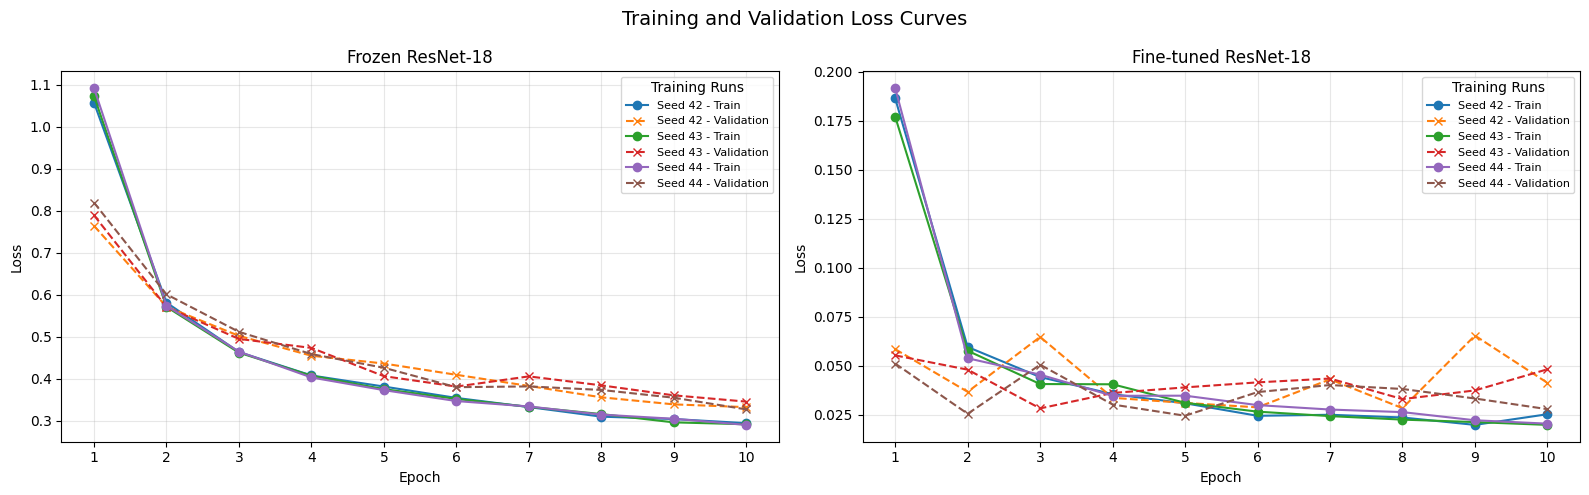

Loss curves saved successfully.


In [39]:
# --------------------------------------------------
# 6.6 Plotting Training and Validation Loss Curves
# --------------------------------------------------

# Create directory for saving figures
os.makedirs("figures", exist_ok=True)

# Create comparison plots
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

experiments = [
    (frozen_results, "Frozen ResNet-18"),
    (finetuned_results, "Fine-tuned ResNet-18")
]

for ax, (results, experiment_name) in zip(axes, experiments):

    for seed in RANDOM_SEEDS:

        history = results[seed]["history"]
        epochs = range(1, len(history["train_loss"]) + 1)

        # Plot training loss
        ax.plot(
            epochs,
            history["train_loss"],
            marker="o",
            label=f"Seed {seed} - Train"
        )

        # Plot validation loss
        ax.plot(
            epochs,
            history["val_loss"],
            marker="x",
            linestyle="--",
            label=f"Seed {seed} - Validation"
        )

    ax.set_title(experiment_name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.set_xticks(range(1, NUM_EPOCHS + 1))
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8, title="Training Runs")

plt.suptitle(
    "Training and Validation Loss Curves",
    fontsize=14
)

plt.tight_layout()

# Save the figure
plt.savefig(
    "figures/loss_curves_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Loss curves saved successfully.")

The loss curves show that both models learned successfully over the training period. However, the fine-tuned ResNet-18 achieved substantially lower training and validation losses, indicating more effective adaptation to the BloodMNIST dataset. Some fluctuations in validation loss were observed across epochs, particularly for Seed 44, highlighting variations in generalisation performance.

### 6.7 Saving Best Model Checkpoints and Training Histories

The best model checkpoint from each training run was saved based on validation accuracy. Training histories were exported as CSV files to preserve epoch-wise training and validation loss and accuracy.

Separate checkpoint and history files were maintained for each random seed and experimental approach. The saved files support reproducibility, performance analysis, and subsequent model evaluation.

In [40]:
# --------------------------------------------------
# 6.7 Saving Best Model Checkpoints and Training Histories
# --------------------------------------------------

import os

# Create directories for checkpoints and training histories
os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs("results/histories", exist_ok=True)

# Combine both experiments
all_results = {
    "frozen": frozen_results,
    "finetuned": finetuned_results
}

saved_history_files = []
verified_checkpoints = []

for experiment_name, experiment_results in all_results.items():

    for seed in RANDOM_SEEDS:

        result = experiment_results[seed]

        # Save epoch-wise training history as CSV
        history_df = pd.DataFrame(result["history"])

        history_path = (
            f"results/histories/"
            f"{experiment_name}_seed_{seed}_history.csv"
        )

        history_df.to_csv(history_path, index=False)

        # Verify history file
        assert os.path.exists(history_path), (
            f"History file not found: {history_path}"
        )

        assert os.path.getsize(history_path) > 0, (
            f"History file is empty: {history_path}"
        )

        saved_history_files.append(history_path)

        # Verify model checkpoint
        checkpoint_path = result["checkpoint"]

        assert os.path.exists(checkpoint_path), (
            f"Checkpoint not found: {checkpoint_path}"
        )

        assert os.path.getsize(checkpoint_path) > 0, (
            f"Checkpoint file is empty: {checkpoint_path}"
        )

        verified_checkpoints.append(checkpoint_path)

        print(f"Checkpoint verified: {checkpoint_path}")
        print(f"History saved: {history_path}")


# Final verification
assert len(verified_checkpoints) == 6
assert len(saved_history_files) == 6

print("\nAll training histories exported successfully.")
print("Total verified checkpoints:", len(verified_checkpoints))
print("Total saved history files:", len(saved_history_files))

Checkpoint verified: results/checkpoints/frozen_resnet18_seed_42.pth
History saved: results/histories/frozen_seed_42_history.csv
Checkpoint verified: results/checkpoints/frozen_resnet18_seed_43.pth
History saved: results/histories/frozen_seed_43_history.csv
Checkpoint verified: results/checkpoints/frozen_resnet18_seed_44.pth
History saved: results/histories/frozen_seed_44_history.csv
Checkpoint verified: results/checkpoints/finetuned_resnet18_seed_42.pth
History saved: results/histories/finetuned_seed_42_history.csv
Checkpoint verified: results/checkpoints/finetuned_resnet18_seed_43.pth
History saved: results/histories/finetuned_seed_43_history.csv
Checkpoint verified: results/checkpoints/finetuned_resnet18_seed_44.pth
History saved: results/histories/finetuned_seed_44_history.csv

All training histories exported successfully.
Total verified checkpoints: 6
Total saved history files: 6


# 7. Model Evaluation

This section evaluates the frozen and fine-tuned ResNet-18 models using the independent BloodMNIST test dataset. Performance is assessed using accuracy, precision, recall, F1-score, classification reports and confusion matrices. Results across the three random seeds are compared to examine model performance and consistency.

## 7.1 Loading the Best Saved Model Checkpoints

The best checkpoints selected based on validation accuracy are loaded for each random seed. Both frozen and fine-tuned ResNet-18 models are reconstructed with the same architecture used during training, and their saved model weights are restored.

The models are set to evaluation mode and prepared for evaluation on the independent, cleaned BloodMNIST test dataset. The test dataset is used only for final performance assessment and is not involved in model selection.

In [41]:
# --------------------------------------------------
# 7.1 Loading the Best Saved Model Checkpoints
# --------------------------------------------------

# Define the class names
CLASS_NAMES = [
    "Basophil",
    "Eosinophil",
    "Erythroblast",
    "Immature Granulocytes",
    "Lymphocyte",
    "Monocyte",
    "Neutrophil",
    "Platelet"
]

NUM_CLASSES = len(CLASS_NAMES)


# Function to load a saved ResNet-18 checkpoint
def load_resnet_checkpoint(checkpoint_path):

    # Verify checkpoint exists
    assert os.path.exists(checkpoint_path), (
        f"Checkpoint not found: {checkpoint_path}"
    )

    # Reconstruct ResNet-18 architecture
    model = models.resnet18(weights=None)
    model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)

    # Load saved checkpoint
    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=True
    )

    # Verify checkpoint contents
    assert "model_state_dict" in checkpoint, (
        "Model state dictionary not found in checkpoint."
    )

    # Restore trained weights
    model.load_state_dict(checkpoint["model_state_dict"])

    # Move model to device and set evaluation mode
    model = model.to(DEVICE)
    model.eval()

    return model


print("Checkpoint loading function defined successfully.")

Checkpoint loading function defined successfully.


In [42]:
# Load frozen and fine-tuned ResNet-18 models for all three seeds

frozen_models = {}
finetuned_models = {}

for seed in RANDOM_SEEDS:

    # Load frozen model
    frozen_path = f"results/checkpoints/frozen_resnet18_seed_{seed}.pth"
    frozen_models[seed] = load_resnet_checkpoint(frozen_path)

    # Load fine-tuned model
    finetuned_path = f"results/checkpoints/finetuned_resnet18_seed_{seed}.pth"
    finetuned_models[seed] = load_resnet_checkpoint(finetuned_path)

print("All six models loaded successfully.")
print("Frozen models:", list(frozen_models.keys()))
print("Fine-tuned models:", list(finetuned_models.keys()))
print("Evaluation device:", DEVICE)

All six models loaded successfully.
Frozen models: [42, 43, 44]
Fine-tuned models: [42, 43, 44]
Evaluation device: cuda


## 7.2 Evaluating on the Independent Test Set

All six trained models are evaluated using the independent, cleaned BloodMNIST test dataset containing 3,415 images. The test dataset is reserved exclusively for final performance evaluation and is not used during model training, hyperparameter selection, or checkpoint selection.

Predictions and corresponding true labels are collected for each model and random seed. These predictions are subsequently used to calculate evaluation metrics and compare the performance of the frozen and fine-tuned ResNet-18 models.

In [43]:
# --------------------------------------------------
# 7.2 Evaluating on the Independent Test Set
# --------------------------------------------------

def get_predictions(model, dataloader, device):

    model.eval()

    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for images, labels in tqdm(dataloader):

            images = images.to(device)

            outputs = model(images)
            predictions = torch.argmax(outputs, dim=1)

            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    return np.array(all_labels), np.array(all_predictions)


# Verify cleaned test dataset size
assert len(test_dataset) == 3415, (
    "Unexpected test dataset size."
)

# Store predictions and true labels for each experiment and seed
test_results = {
    "frozen": {},
    "finetuned": {}
}

reference_labels = None

for experiment_name, models_dict in [
    ("frozen", frozen_models),
    ("finetuned", finetuned_models)
]:

    for seed in RANDOM_SEEDS:

        model = models_dict[seed]

        print(f"\nEvaluating {experiment_name} model - Seed {seed}")

        y_true, y_pred = get_predictions(
            model, test_loader, DEVICE
        )

        # Verify number of evaluated samples
        assert len(y_true) == 3415
        assert len(y_pred) == 3415

        # Verify label and prediction ranges
        assert np.all((y_true >= 0) & (y_true < NUM_CLASSES))
        assert np.all((y_pred >= 0) & (y_pred < NUM_CLASSES))

        # Ensure all six models use identical test labels
        if reference_labels is None:
            reference_labels = y_true.copy()
        else:
            assert np.array_equal(reference_labels, y_true), (
                "Test labels differ between model evaluations."
            )

        test_results[experiment_name][seed] = {
            "y_true": y_true,
            "y_pred": y_pred
        }

        accuracy = accuracy_score(y_true, y_pred)

        print(f"Test samples evaluated: {len(y_true)}")
        print(f"Test accuracy: {accuracy * 100:.2f}%")

print("\nEvaluation of all six models completed.")
print("All models evaluated on the same 3,415 test samples.")


Evaluating frozen model - Seed 42


  0%|          | 0/54 [00:00<?, ?it/s]

Test samples evaluated: 3415
Test accuracy: 88.84%

Evaluating frozen model - Seed 43


  0%|          | 0/54 [00:00<?, ?it/s]

Test samples evaluated: 3415
Test accuracy: 88.84%

Evaluating frozen model - Seed 44


  0%|          | 0/54 [00:00<?, ?it/s]

... (3 outputs left out)

  0%|          | 0/54 [00:00<?, ?it/s]

Test samples evaluated: 3415
Test accuracy: 98.80%

Evaluating finetuned model - Seed 44


  0%|          | 0/54 [00:00<?, ?it/s]

Test samples evaluated: 3415
Test accuracy: 98.80%

Evaluation of all six models completed.
All models evaluated on the same 3,415 test samples.


## 7.3 Accuracy, Precision, Recall and F1-Score

Accuracy, macro-averaged precision, macro-averaged recall, and macro-averaged F1-score are calculated for each model and random seed using the independent test dataset. These metrics provide an overall comparison of classification performance across the eight blood cell classes.

The mean and standard deviation across the three random seeds are calculated to assess the consistency of each experimental approach.

In [44]:
# Calculate evaluation metrics for all six models

metric_results = []

for experiment_name in ["frozen", "finetuned"]:
    for seed in RANDOM_SEEDS:

        y_true = test_results[experiment_name][seed]["y_true"]
        y_pred = test_results[experiment_name][seed]["y_pred"]

        accuracy = accuracy_score(y_true, y_pred)
        precision = precision_score(
            y_true, y_pred, average="macro", zero_division=0
        )
        recall = recall_score(
            y_true, y_pred, average="macro", zero_division=0
        )
        f1 = f1_score(
            y_true, y_pred, average="macro", zero_division=0
        )

        metric_results.append({
            "Model": experiment_name.capitalize(),
            "Seed": seed,
            "Accuracy (%)": accuracy * 100,
            "Precision (%)": precision * 100,
            "Recall (%)": recall * 100,
            "F1-Score (%)": f1 * 100
        })

metrics_df = pd.DataFrame(metric_results)

print("MODEL PERFORMANCE COMPARISON")
display(metrics_df.round(2))

# Calculate mean and standard deviation across seeds
summary_df = metrics_df.groupby("Model").agg({
    "Accuracy (%)": ["mean", "std"],
    "Precision (%)": ["mean", "std"],
    "Recall (%)": ["mean", "std"],
    "F1-Score (%)": ["mean", "std"]
})

print("\nMEAN AND STANDARD DEVIATION ACROSS THREE SEEDS")
display(summary_df.round(2))


MODEL PERFORMANCE COMPARISON


,Model,Seed,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
0,Frozen,42,88.84,89.71,86.85,88.00
1,Frozen,43,88.84,90.27,86.30,87.57
2,Frozen,44,89.22,89.80,88.03,88.75
3,Finetuned,42,98.83,98.99,98.85,98.92
4,Finetuned,43,98.80,99.02,98.85,98.92
5,Finetuned,44,98.80,98.94,98.84,98.88



MEAN AND STANDARD DEVIATION ACROSS THREE SEEDS


Accuracy (%)       Precision (%)       Recall (%)        \
                  mean   std          mean   std       mean   std   
Model                                                               
Finetuned        98.81  0.02         98.98  0.04      98.84  0.01   
Frozen           88.97  0.22         89.93  0.30      87.06  0.88   

          F1-Score (%)        
                  mean   std  
Model                         
Finetuned        98.91  0.02  
Frozen           88.11  0.60

## 7.4 Classification Reports

Classification reports are generated for each model and random seed to examine class-wise precision, recall and F1-score. These reports provide detailed insights into the classification performance of individual blood cell types and help identify classes that are more difficult to classify.

In [62]:
# Generate classification reports for all six models

classification_reports = {
    "frozen": {},
    "finetuned": {}
}

for experiment_name in ["frozen", "finetuned"]:

    for seed in RANDOM_SEEDS:

        print("\n" + "=" * 65)
        print(f"{experiment_name.upper()} RESNET-18 - SEED {seed}")
        print("=" * 65)

        y_true = test_results[experiment_name][seed]["y_true"]
        y_pred = test_results[experiment_name][seed]["y_pred"]

        report = classification_report(
            y_true,
            y_pred,
            labels=np.arange(len(CLASS_NAMES)),
            target_names=CLASS_NAMES,
            zero_division=0,
            output_dict=True
        )

        classification_reports[experiment_name][seed] = report

        print(classification_report(
            y_true,
            y_pred,
            labels=np.arange(len(CLASS_NAMES)),
            target_names=CLASS_NAMES,
            zero_division=0
        ))

print("\nAll classification reports generated successfully.")


FROZEN RESNET-18 - SEED 42
                       precision    recall  f1-score   support

             Basophil       0.92      0.73      0.81       241
           Eosinophil       0.93      0.93      0.93       622
         Erythroblast       0.90      0.89      0.89       311
Immature Granulocytes       0.77      0.84      0.80       579
           Lymphocyte       0.91      0.90      0.90       243
             Monocyte       0.91      0.74      0.81       284
           Neutrophil       0.89      0.94      0.91       665
             Platelet       0.96      0.98      0.97       470

             accuracy                           0.89      3415
            macro avg       0.90      0.87      0.88      3415
         weighted avg       0.89      0.89      0.89      3415


FROZEN RESNET-18 - SEED 43
                       precision    recall  f1-score   support

             Basophil       0.93      0.70      0.80       241
           Eosinophil       0.93      0.95      0.94      

## 7.5 Confusion Matrices

Confusion matrices are generated to examine the classification performance of each model across the eight blood cell classes. They show the number of correctly and incorrectly classified images, helping identify commonly confused blood cell types. The matrices are compared between frozen and fine-tuned ResNet-18 models.

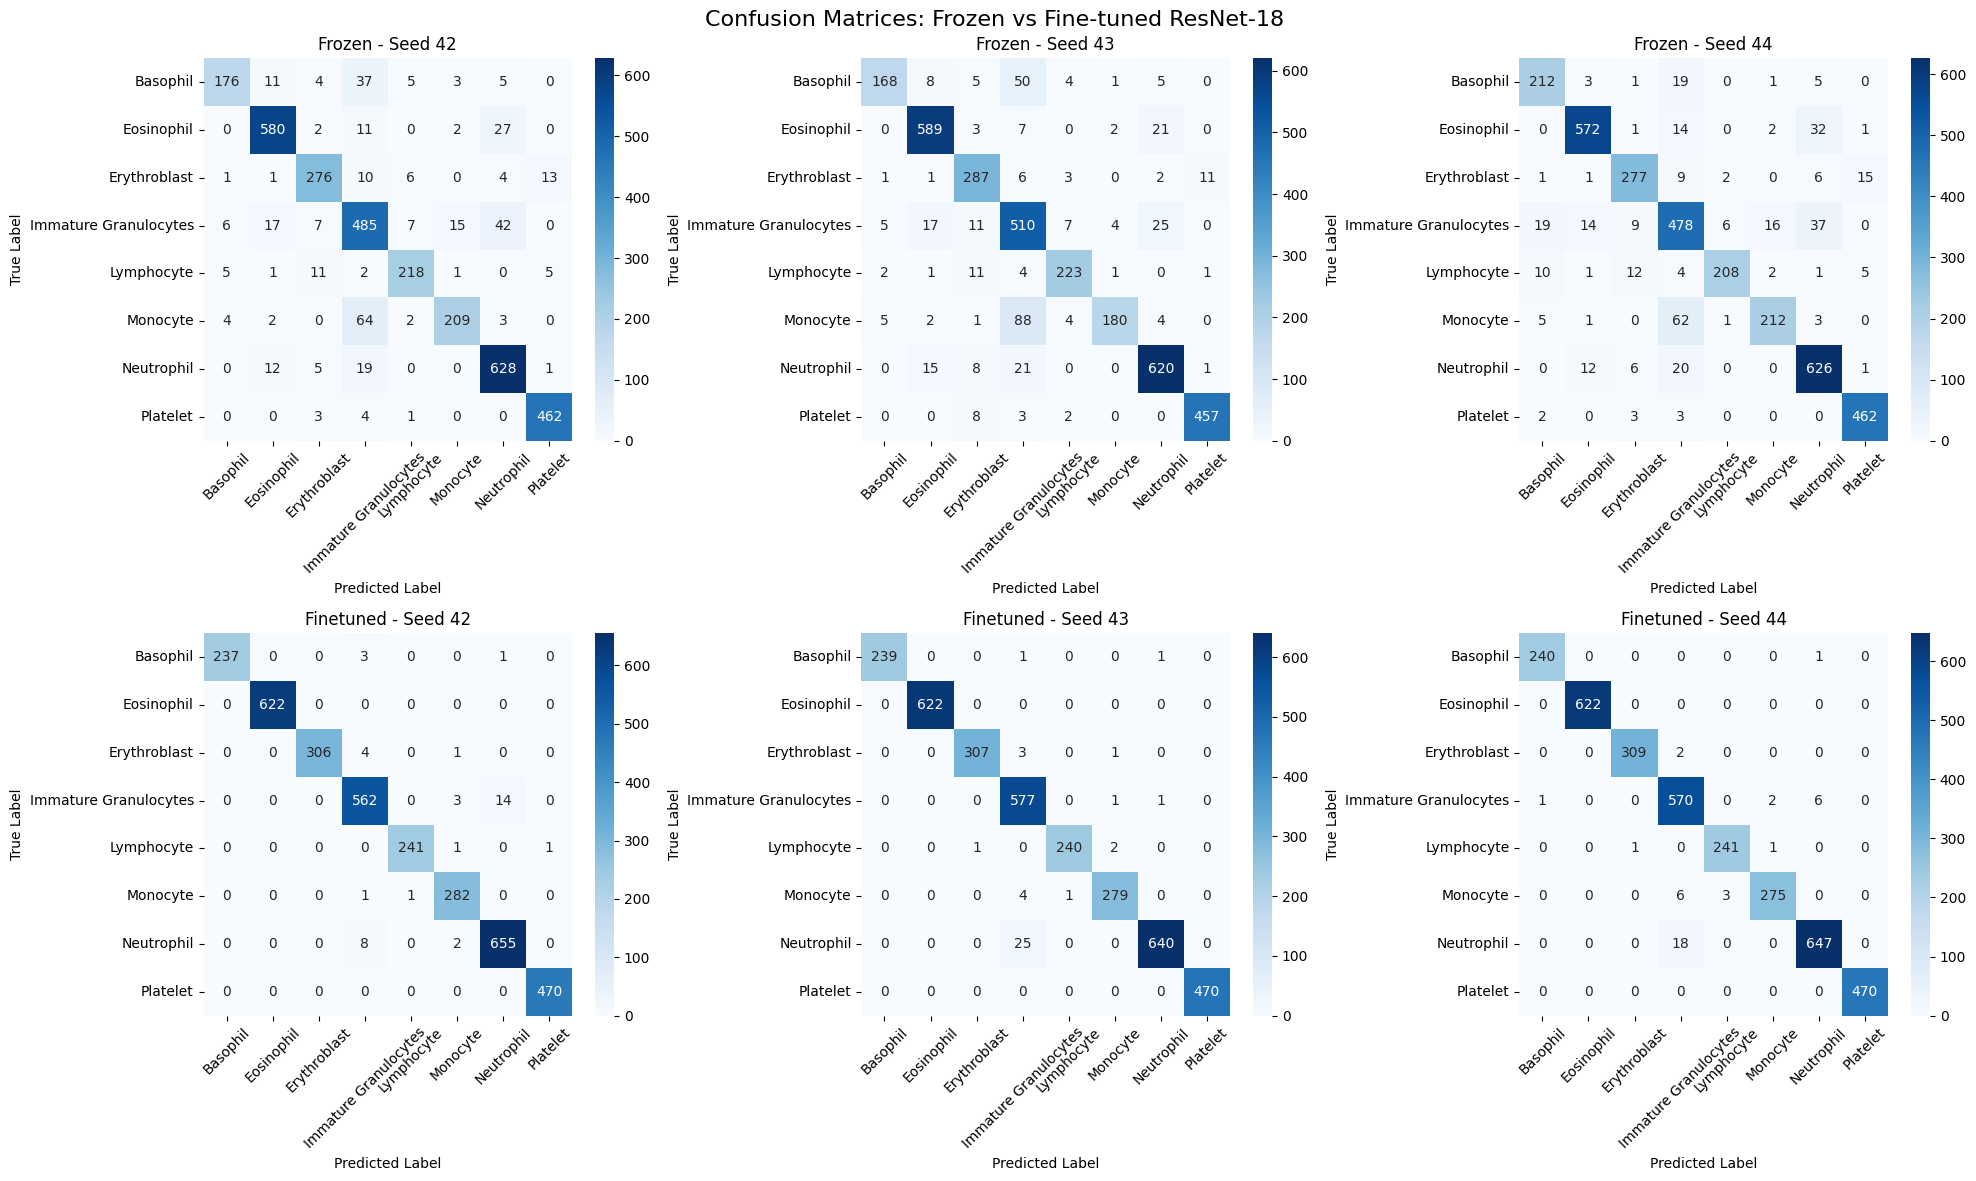

Confusion matrices saved successfully.


In [63]:
# Generate confusion matrices for all six models

import os

os.makedirs("figures", exist_ok=True)

fig, axes = plt.subplots(2, 3, figsize=(20, 12))

for row, experiment_name in enumerate(["frozen", "finetuned"]):

    for col, seed in enumerate(RANDOM_SEEDS):

        y_true = test_results[experiment_name][seed]["y_true"]
        y_pred = test_results[experiment_name][seed]["y_pred"]

        cm = confusion_matrix(
            y_true,
            y_pred,
            labels=range(len(CLASS_NAMES))
        )

        sns.heatmap(
            cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            xticklabels=CLASS_NAMES,
            yticklabels=CLASS_NAMES,
            ax=axes[row, col]
        )

        axes[row, col].set_title(
            f"{experiment_name.capitalize()} - Seed {seed}"
        )
        axes[row, col].set_xlabel("Predicted Label")
        axes[row, col].set_ylabel("True Label")

        axes[row, col].tick_params(axis="x", rotation=45)
        axes[row, col].tick_params(axis="y", rotation=0)

plt.suptitle(
    "Confusion Matrices: Frozen vs Fine-tuned ResNet-18",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    "figures/confusion_matrices_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrices saved successfully.")

## 7.6 Class-wise Performance Analysis

Class-wise precision, recall and F1-scores are compared between frozen and fine-tuned ResNet-18 models. The results across all three random seeds are used to examine performance differences for each blood cell category and identify classes with comparatively lower classification performance.

In [64]:
# Calculate class-wise metrics averaged across three random seeds

class_metrics = []

for experiment_name in ["frozen", "finetuned"]:

    for seed in RANDOM_SEEDS:

        report = classification_reports[experiment_name][seed]

        for class_name in CLASS_NAMES:

            class_metrics.append({
                "Model": experiment_name.capitalize(),
                "Seed": seed,
                "Class": class_name,
                "Precision": report[class_name]["precision"],
                "Recall": report[class_name]["recall"],
                "F1-score": report[class_name]["f1-score"]
            })

class_metrics_df = pd.DataFrame(class_metrics)

# Calculate mean class-wise performance across seeds
class_summary = (
    class_metrics_df
    .groupby(["Model", "Class"])[["Precision", "Recall", "F1-score"]]
    .mean()
    .reset_index()
)

print("MEAN CLASS-WISE PERFORMANCE ACROSS THREE SEEDS")
display(class_summary.round(4))

MEAN CLASS-WISE PERFORMANCE ACROSS THREE SEEDS


,Model,Class,Precision,Recall,F1-score
0,Finetuned,Basophil,0.9986,0.9903,0.9944
1,Finetuned,Eosinophil,1.0000,1.0000,1.0000
2,Finetuned,Erythroblast,0.9978,0.9882,0.9930
3,Finetuned,Immature Granulocytes,0.9582,0.9839,0.9708
4,Finetuned,Lymphocyte,0.9931,0.9904,0.9918
5,Finetuned,Monocyte,0.9836,0.9812,0.9824
6,Finetuned,Neutrophil,0.9879,0.9734,0.9806
7,Finetuned,Platelet,0.9993,1.0000,0.9996
8,Frozen,Basophil,0.8987,0.7690,0.8248
9,Frozen,Eosinophil,0.9357,0.9330,0.9342


## 7.7 Summary of Results Across Multiple Seeds

The evaluation metrics from all three random seeds are summarised to compare the overall performance and consistency of frozen and fine-tuned ResNet-18 models. Mean and standard deviation values are used to report performance across repeated training runs.

In [65]:
# Summarise test performance across three random seeds

import os

os.makedirs("results", exist_ok=True)

final_summary = metrics_df.groupby("Model").agg({
    "Accuracy (%)": ["mean", "std"],
    "Precision (%)": ["mean", "std"],
    "Recall (%)": ["mean", "std"],
    "F1-Score (%)": ["mean", "std"]
})

print("FINAL TEST PERFORMANCE SUMMARY")
display(final_summary.round(2))

# Save summary to CSV
final_summary.to_csv("results/final_test_performance_summary.csv")

print("\nFinal performance summary saved successfully.")

FINAL TEST PERFORMANCE SUMMARY


Accuracy (%)       Precision (%)       Recall (%)        \
                  mean   std          mean   std       mean   std   
Model                                                               
Finetuned        98.81  0.02         98.98  0.04      98.84  0.01   
Frozen           88.97  0.22         89.93  0.30      87.06  0.88   

          F1-Score (%)        
                  mean   std  
Model                         
Finetuned        98.91  0.02  
Frozen           88.11  0.60


Final performance summary saved successfully.


## 7.8 Statistical Analysis Using Bootstrap Confidence Intervals

Bootstrap resampling is used to estimate 95% confidence intervals for test accuracy and macro F1-score using 2,000 resamples. A paired comparison is also performed to estimate the performance difference between frozen and fine-tuned ResNet-18 models.

The same resampled test indices are used for both model configurations and all three random seeds, preserving the paired comparison. The resulting confidence intervals quantify uncertainty due to test-set sampling, conditional on the trained models, rather than capturing all possible variation from model training.

In [66]:
# --------------------------------------------------
# 7.8 Bootstrap Confidence Intervals and Paired
#     Model Comparison
# --------------------------------------------------

import os
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

# Create results directory
os.makedirs("results", exist_ok=True)

# Bootstrap settings
N_BOOTSTRAPS = 2000
CONFIDENCE_LEVEL = 95
rng = np.random.default_rng(42)

# Verify that all models use the same test labels
y_true_reference = test_results["frozen"][RANDOM_SEEDS[0]]["y_true"]
n_samples = len(y_true_reference)

for experiment in ["frozen", "finetuned"]:
    for seed in RANDOM_SEEDS:
        assert np.array_equal(
            test_results[experiment][seed]["y_true"],
            y_true_reference
        ), "Test labels differ between model runs."

print(f"Number of test samples: {n_samples}")
print(f"Number of bootstrap resamples: {N_BOOTSTRAPS}")

# Store bootstrap results
bootstrap_scores = {
    "frozen": {"accuracy": [], "macro_f1": []},
    "finetuned": {"accuracy": [], "macro_f1": []}
}

bootstrap_differences = {
    "accuracy": [],
    "macro_f1": []
}

# Perform paired bootstrap resampling
for _ in range(N_BOOTSTRAPS):

    # Sample test indices with replacement
    indices = rng.integers(0, n_samples, size=n_samples)
    y_boot = y_true_reference[indices]

    seed_scores = {
        "frozen": {"accuracy": [], "macro_f1": []},
        "finetuned": {"accuracy": [], "macro_f1": []}
    }

    for experiment in ["frozen", "finetuned"]:

        for seed in RANDOM_SEEDS:

            y_pred = test_results[experiment][seed]["y_pred"][indices]

            seed_scores[experiment]["accuracy"].append(
                accuracy_score(y_boot, y_pred)
            )

            seed_scores[experiment]["macro_f1"].append(
                f1_score(
                    y_boot,
                    y_pred,
                    labels=np.arange(len(CLASS_NAMES)),
                    average="macro",
                    zero_division=0
                )
            )

    # Average performance across the three seeds
    for experiment in ["frozen", "finetuned"]:

        for metric in ["accuracy", "macro_f1"]:

            bootstrap_scores[experiment][metric].append(
                np.mean(seed_scores[experiment][metric])
            )

    # Paired difference: fine-tuned minus frozen
    for metric in ["accuracy", "macro_f1"]:

        difference = (
            np.mean(seed_scores["finetuned"][metric])
            - np.mean(seed_scores["frozen"][metric])
        )

        bootstrap_differences[metric].append(difference)


# Calculate percentile confidence intervals
lower_percentile = (100 - CONFIDENCE_LEVEL) / 2
upper_percentile = 100 - lower_percentile

results = []

for metric in ["accuracy", "macro_f1"]:

    for experiment in ["frozen", "finetuned"]:

        values = np.array(bootstrap_scores[experiment][metric])

        results.append({
            "Metric": metric,
            "Model": experiment.capitalize(),
            "Mean (%)": values.mean() * 100,
            "95% CI Lower (%)": np.percentile(
                values, lower_percentile
            ) * 100,
            "95% CI Upper (%)": np.percentile(
                values, upper_percentile
            ) * 100
        })

    # Confidence interval for paired performance difference
    differences = np.array(bootstrap_differences[metric])

    results.append({
        "Metric": metric,
        "Model": "Fine-tuned - Frozen",
        "Mean (%)": differences.mean() * 100,
        "95% CI Lower (%)": np.percentile(
            differences, lower_percentile
        ) * 100,
        "95% CI Upper (%)": np.percentile(
            differences, upper_percentile
        ) * 100
    })


# Create and display summary
bootstrap_summary = pd.DataFrame(results)

print("\nBOOTSTRAP RESULTS (2,000 RESAMPLES)")
display(bootstrap_summary.round(2))


# Interpret paired differences
print("\nINTERPRETATION OF PAIRED DIFFERENCES")

for metric in ["accuracy", "macro_f1"]:

    differences = np.array(bootstrap_differences[metric])

    lower = np.percentile(
        differences, lower_percentile
    ) * 100

    upper = np.percentile(
        differences, upper_percentile
    ) * 100

    if lower > 0:
        conclusion = "Fine-tuned model shows a positive improvement."

    elif upper < 0:
        conclusion = "Frozen model shows a positive improvement."

    else:
        conclusion = "The confidence interval includes zero."

    print(
        f"{metric}: 95% CI for improvement = "
        f"[{lower:.2f}, {upper:.2f}] percentage points. "
        f"{conclusion}"
    )


# Save bootstrap results
bootstrap_summary.to_csv(
    "results/bootstrap_confidence_intervals.csv",
    index=False
)

print("\nBootstrap results saved successfully.")

Number of test samples: 3415
Number of bootstrap resamples: 2000

BOOTSTRAP RESULTS (2,000 RESAMPLES)


,Metric,Model,Mean (%),95% CI Lower (%),95% CI Upper (%)
0,accuracy,Frozen,88.98,88.00,89.95
1,accuracy,Finetuned,98.80,98.48,99.08
2,accuracy,Fine-tuned - Frozen,9.82,8.87,10.80
3,macro_f1,Frozen,88.11,87.02,89.15
4,macro_f1,Finetuned,98.90,98.59,99.17
5,macro_f1,Fine-tuned - Frozen,10.79,9.75,11.84



INTERPRETATION OF PAIRED DIFFERENCES
accuracy: 95% CI for improvement = [8.87, 10.80] percentage points. Fine-tuned model shows a positive improvement.
macro_f1: 95% CI for improvement = [9.75, 11.84] percentage points. Fine-tuned model shows a positive improvement.

Bootstrap results saved successfully.


## 7.9 Immature Granulocyte Recall and 95% Confidence Interval

Immature granulocytes were selected as the focus class for a more detailed evaluation. Their class-specific recall is examined for both frozen and fine-tuned ResNet-18 models across the three random seeds.

A 95% bootstrap confidence interval is calculated for the mean recall across the three seeds using 2,000 resamples of the true immature granulocyte test examples. This analysis provides additional insight into the models' ability to correctly identify this specific blood cell category.

In [67]:
# --------------------------------------------------
# 7.9 Immature Granulocyte Recall and 95% CI
# --------------------------------------------------

import numpy as np
import pandas as pd

# Identify focus class
FOCUS_CLASS = "Immature Granulocytes"
FOCUS_CLASS_INDEX = CLASS_NAMES.index(FOCUS_CLASS)

N_BOOTSTRAPS = 2000
rng = np.random.default_rng(42)

# Verify the test labels are consistent
y_true_reference = test_results["frozen"][RANDOM_SEEDS[0]]["y_true"]

focus_indices = np.where(
    y_true_reference == FOCUS_CLASS_INDEX
)[0]

n_focus_samples = len(focus_indices)

assert n_focus_samples > 0, "No immature granulocyte test samples found."

print(f"Focus class: {FOCUS_CLASS}")
print(f"Number of true test examples: {n_focus_samples}")

# Store observed recall for each seed
focus_recall_results = []

# Store bootstrap recall across seeds
bootstrap_recall = {
    "frozen": [],
    "finetuned": []
}

for experiment in ["frozen", "finetuned"]:

    # Calculate observed recall for each seed
    seed_recalls = []

    for seed in RANDOM_SEEDS:

        y_true = test_results[experiment][seed]["y_true"]
        y_pred = test_results[experiment][seed]["y_pred"]

        assert np.array_equal(
            y_true, y_true_reference
        ), "Test labels differ between model runs."

        # Recall = correctly predicted focus-class examples
        # divided by all true focus-class examples
        recall = np.mean(
            y_pred[focus_indices] == FOCUS_CLASS_INDEX
        )

        seed_recalls.append(recall)

        focus_recall_results.append({
            "Model": experiment.capitalize(),
            "Seed": seed,
            "Recall (%)": recall * 100
        })

    # Bootstrap the mean recall across the three seeds
    experiment_bootstrap = []

    for _ in range(N_BOOTSTRAPS):

        sampled_indices = rng.choice(
            focus_indices,
            size=n_focus_samples,
            replace=True
        )

        sampled_seed_recalls = []

        for seed in RANDOM_SEEDS:

            y_pred = test_results[experiment][seed]["y_pred"]

            sampled_recall = np.mean(
                y_pred[sampled_indices] == FOCUS_CLASS_INDEX
            )

            sampled_seed_recalls.append(sampled_recall)

        experiment_bootstrap.append(
            np.mean(sampled_seed_recalls)
        )

    bootstrap_recall[experiment] = experiment_bootstrap


# Display recall for each seed
focus_recall_df = pd.DataFrame(focus_recall_results)

print("\nIMMATURE GRANULOCYTE RECALL BY SEED")
display(focus_recall_df.round(2))


# Calculate mean recall and 95% bootstrap confidence intervals
summary_results = []

for experiment in ["frozen", "finetuned"]:

    values = np.array(bootstrap_recall[experiment])

    observed_mean = focus_recall_df[
        focus_recall_df["Model"] == experiment.capitalize()
    ]["Recall (%)"].mean()

    lower_ci, upper_ci = np.percentile(
        values, [2.5, 97.5]
    )

    summary_results.append({
        "Model": experiment.capitalize(),
        "Mean Recall (%)": observed_mean,
        "95% CI Lower (%)": lower_ci * 100,
        "95% CI Upper (%)": upper_ci * 100
    })


focus_recall_summary = pd.DataFrame(summary_results)

print("\nMEAN IMMATURE GRANULOCYTE RECALL WITH 95% BOOTSTRAP CI")
display(focus_recall_summary.round(2))


# Save results
focus_recall_df.to_csv(
    "results/immature_granulocyte_recall_by_seed.csv",
    index=False
)

focus_recall_summary.to_csv(
    "results/immature_granulocyte_recall_summary.csv",
    index=False
)

print("\nImmature granulocyte recall results saved successfully.")

Focus class: Immature Granulocytes
Number of true test examples: 579

IMMATURE GRANULOCYTE RECALL BY SEED


,Model,Seed,Recall (%)
0,Frozen,42,83.77
1,Frozen,43,88.08
2,Frozen,44,82.56
3,Finetuned,42,97.06
4,Finetuned,43,99.65
5,Finetuned,44,98.45



MEAN IMMATURE GRANULOCYTE RECALL WITH 95% BOOTSTRAP CI


,Model,Mean Recall (%),95% CI Lower (%),95% CI Upper (%)
0,Frozen,84.80,81.98,87.56
1,Finetuned,98.39,97.58,99.08



Immature granulocyte recall results saved successfully.


## 7.10 Final Evaluation Summary

The evaluation results provide an overall comparison of frozen and fine-tuned ResNet-18 models on the cleaned BloodMNIST test set.

Overall performance is examined using accuracy, macro precision, macro recall and macro F1-score. Mean and standard deviation across three random seeds are used to assess consistency between repeated training runs. Bootstrap confidence intervals provide additional information about uncertainty in test-set performance and the difference between the two model configurations.

Class-wise evaluation highlights differences in the classification performance of individual blood cell categories. Particular attention is given to immature granulocytes through the analysis of class-specific recall and its 95% bootstrap confidence interval.

The findings are interpreted within the scope of the BloodMNIST dataset. Although the results allow comparison of the two ResNet-18 training strategies, evaluation on independent clinical datasets would be required to establish generalisation beyond this dataset.

# 8. Explainability and Error Analysis

This section investigates the decision-making behaviour of the fine-tuned ResNet-18 model using Gradient-weighted Class Activation Mapping (Grad-CAM). Correctly and incorrectly classified test images are examined to understand the image regions influencing model predictions and identify potential classification errors or visual shortcuts.
## 8.1 Understanding Grad-CAM

Grad-CAM (Gradient-weighted Class Activation Mapping) is a visual explanation technique used to highlight image regions that contribute to a model's prediction. It uses gradients flowing into the final convolutional layer to generate a heatmap showing areas that have a strong influence on the predicted class.

In this project, Grad-CAM is used to examine whether the fine-tuned ResNet-18 model focuses on relevant blood cell structures when classifying BloodMNIST images.

## 8.2 Implementing Grad-CAM for ResNet-18

Grad-CAM is implemented using the final convolutional layer (layer4) of ResNet-18. Forward and backward hooks are used to capture feature activations and their corresponding gradients. These are combined to generate a class-specific heatmap highlighting image regions that influence the model's prediction.

In [68]:
import torch
import torch.nn.functional as F


class GradCAM:
    def __init__(self, model, target_layer):

        # Store the trained model and the target convolutional layer
        self.model = model
        self.target_layer = target_layer

        # Initialise variables to store feature activations and gradients
        self.activations = None
        self.gradients = None

        # Register a forward hook to capture feature activations
        self.forward_hook = target_layer.register_forward_hook(
            self.save_activations
        )

        # Register a backward hook to capture gradients
        self.backward_hook = target_layer.register_full_backward_hook(
            self.save_gradients
        )

    def save_activations(self, module, input, output):

        # Store the feature maps generated during the forward pass
        self.activations = output.detach()

    def save_gradients(self, module, grad_input, grad_output):

        # Store the gradients calculated during the backward pass
        self.gradients = grad_output[0].detach()

    def generate(self, image, class_idx=None):

        # Check that the input contains exactly one image
        # Expected input shape: [1, C, H, W]
        if image.ndim != 4 or image.shape[0] != 1:
            raise ValueError(
                "Grad-CAM expects one image with shape [1, C, H, W]."
            )

        # Set the model to evaluation mode
        self.model.eval()

        # Clear previously accumulated gradients
        self.model.zero_grad(set_to_none=True)

        # Enable gradient calculation for Grad-CAM
        with torch.enable_grad():

            # Perform a forward pass through the model
            output = self.model(image)

            # Select the predicted class if no target class is specified
            if class_idx is None:
                class_idx = output.argmax(dim=1).item()

            # Select the model score corresponding to the target class
            score = output[0, class_idx]

            # Perform backward propagation to calculate gradients
            score.backward()

            # Calculate channel-wise importance weights
            # Global average pooling is applied to the gradients
            weights = self.gradients.mean(
                dim=(2, 3), keepdim=True
            )

            # Combine the importance weights with the feature activations
            # Sum across channels to generate the class activation map
            cam = (weights * self.activations).sum(
                dim=1, keepdim=True
            )

            # Apply ReLU to retain only positive contributions
            cam = F.relu(cam)

            # Resize the heatmap to match the input image dimensions
            cam = F.interpolate(
                cam,
                size=image.shape[2:],
                mode="bilinear",
                align_corners=False
            )

            # Normalize the heatmap values to the range [0, 1]
            cam_min = cam.amin(dim=(2, 3), keepdim=True)
            cam_max = cam.amax(dim=(2, 3), keepdim=True)

            cam = (cam - cam_min) / (cam_max - cam_min + 1e-8)

        # Convert the heatmap into a 2D NumPy array
        # Return the heatmap and the class index used for Grad-CAM
        return cam[0, 0].detach().cpu().numpy(), class_idx

    def remove_hooks(self):

        # Remove registered hooks after Grad-CAM analysis
        # This prevents unnecessary hook accumulation
        self.forward_hook.remove()
        self.backward_hook.remove()


# Load the fine-tuned ResNet-18 model trained with seed 42
gradcam_model = finetuned_models[42]

# Select the final convolutional block (layer4) of ResNet-18
# This layer provides high-level spatial features for Grad-CAM
target_layer = gradcam_model.layer4[-1]

# Initialise the Grad-CAM object using the selected model and target layer
gradcam = GradCAM(gradcam_model, target_layer)

# Confirm successful Grad-CAM initialisation
print("Grad-CAM implementation initialized successfully.")
print("Target layer:", target_layer)


Grad-CAM implementation initialized successfully.
Target layer: BasicBlock(
  (conv1): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (conv2): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn2): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
)


## 8.3 Visualising Correctly Classified Images

Grad-CAM heatmaps are generated for correctly classified test images using the fine-tuned ResNet-18 model. The heatmaps are overlaid on the original images to highlight regions that contribute to the model's predictions.

Number of correctly classified images: 3375


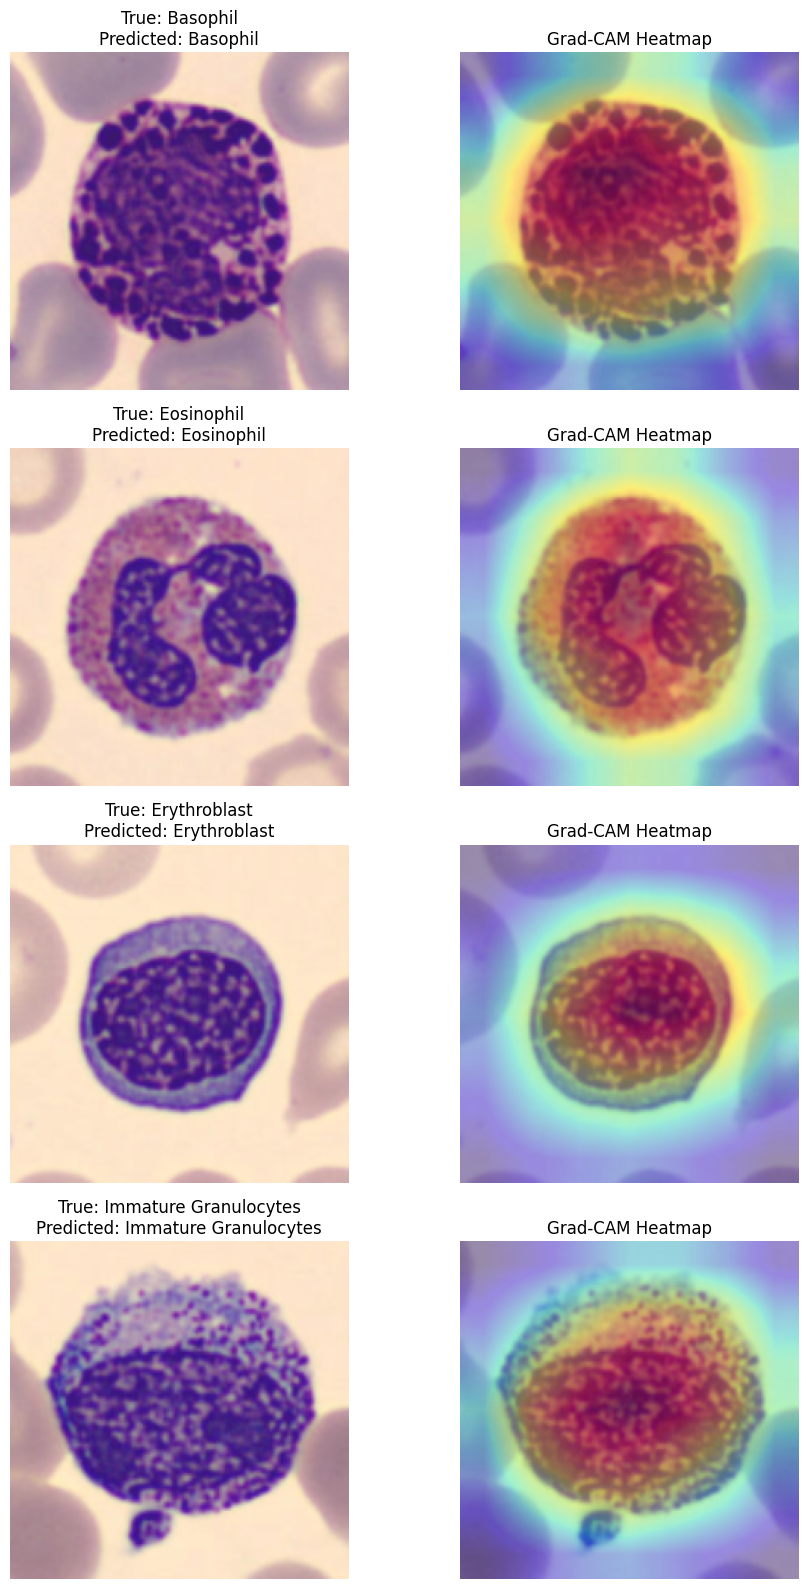

Correct prediction Grad-CAM visualisation completed.


In [69]:
import os

# Create the figures directory if it does not already exist
os.makedirs("figures", exist_ok=True)

# Retrieve true labels and predicted labels for fine-tuned ResNet-18 (Seed 42)
y_true = test_results["finetuned"][42]["y_true"]
y_pred = test_results["finetuned"][42]["y_pred"]

# Identify indices of correctly classified test images
correct_indices = np.where(y_true == y_pred)[0]

print("Number of correctly classified images:", len(correct_indices))


# Select up to four correctly classified images from different classes
# This provides examples from different blood cell categories where possible
selected_correct = []

for class_idx in range(len(CLASS_NAMES)):

    # Find correctly classified images belonging to the current class
    class_correct = correct_indices[
        y_true[correct_indices] == class_idx
    ]

    # Select the first available correctly classified image from this class
    if len(class_correct) > 0:
        selected_correct.append(class_correct[0])

    # Stop after selecting four examples
    if len(selected_correct) == 4:
        break


# Generate Grad-CAM visualisations if correctly classified images are available
if len(selected_correct) == 0:

    print("No correctly classified images available for visualisation.")

else:

    # Create a figure with two columns:
    # Column 1: Original test images
    # Column 2: Grad-CAM heatmap overlays
    fig, axes = plt.subplots(
        len(selected_correct),
        2,
        figsize=(10, 4 * len(selected_correct)),
        squeeze=False
    )

    # Process each selected correctly classified image
    for row, idx in enumerate(selected_correct):

        # Retrieve the image and its true label from the test dataset
        image_tensor, true_label = test_dataset[idx]
        true_label = int(true_label)

        # Add batch dimension and move the image to the computation device
        input_tensor = image_tensor.unsqueeze(0).to(DEVICE)

        # Generate Grad-CAM heatmap for the model's predicted class
        heatmap, predicted_class = gradcam.generate(input_tensor)

        # Convert the normalized image back to its original RGB representation
        image = image_tensor.permute(1, 2, 0).cpu().numpy()
        image = image * np.array(IMAGENET_STD) + np.array(IMAGENET_MEAN)

        # Clip pixel values to the valid display range [0, 1]
        image = np.clip(image, 0, 1)

        # Display the original image with true and predicted class labels
        axes[row, 0].imshow(image)
        axes[row, 0].set_title(
            f"True: {CLASS_NAMES[true_label]}\n"
            f"Predicted: {CLASS_NAMES[predicted_class]}"
        )
        axes[row, 0].axis("off")

        # Overlay the Grad-CAM heatmap on the original image
        # The highlighted regions indicate areas influencing the prediction
        axes[row, 1].imshow(image)
        axes[row, 1].imshow(heatmap, cmap="jet", alpha=0.4)
        axes[row, 1].set_title("Grad-CAM Heatmap")
        axes[row, 1].axis("off")

    # Adjust spacing between images and titles
    plt.tight_layout()

    # Save the Grad-CAM visualisation for correctly classified images
    plt.savefig(
        "figures/gradcam_correct_predictions.png",
        dpi=300,
        bbox_inches="tight"
    )

    # Display the generated visualisations
    plt.show()

    print("Correct prediction Grad-CAM visualisation completed.")


## 8.4 Visualising Incorrectly Classified Images

Grad-CAM heatmaps are generated for incorrectly classified test images using the fine-tuned ResNet-18 model. The visualisations compare the true and predicted classes and highlight image regions that influenced the incorrect predictions. This analysis helps investigate potential reasons for classification errors.

Number of incorrectly classified images: 40


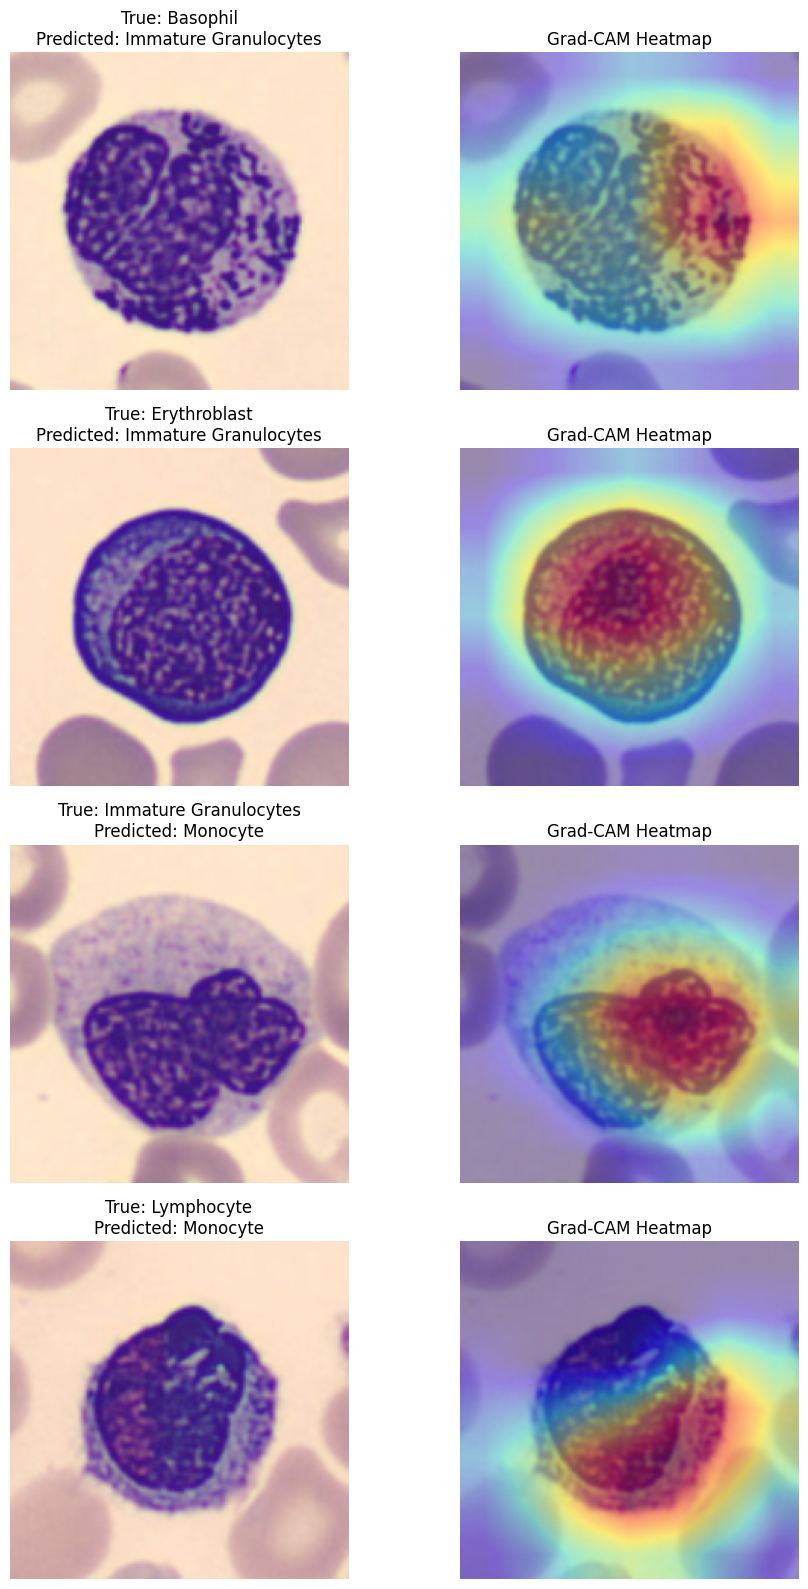

Incorrect prediction Grad-CAM visualisation completed.


In [70]:
import os

# Create the figures directory if it does not already exist
os.makedirs("figures", exist_ok=True)

# Retrieve true labels and predicted labels for fine-tuned ResNet-18 (Seed 42)
y_true = test_results["finetuned"][42]["y_true"]
y_pred = test_results["finetuned"][42]["y_pred"]

# Identify indices of incorrectly classified test images
incorrect_indices = np.where(y_true != y_pred)[0]

print("Number of incorrectly classified images:", len(incorrect_indices))


# Select up to four incorrectly classified images from different true classes
# This provides examples from different blood cell categories where possible
selected_incorrect = []

for class_idx in range(len(CLASS_NAMES)):

    # Find errors belonging to the current true class
    class_errors = incorrect_indices[
        y_true[incorrect_indices] == class_idx
    ]

    # Select the first available error from this class
    if len(class_errors) > 0:
        selected_incorrect.append(class_errors[0])

    # Stop after selecting four examples
    if len(selected_incorrect) == 4:
        break


# Generate Grad-CAM visualisations if incorrect predictions are available
if len(selected_incorrect) == 0:

    print("No incorrectly classified images found.")

else:

    # Create a figure with two columns:
    # Column 1: Original test images
    # Column 2: Grad-CAM heatmap overlays
    fig, axes = plt.subplots(
        len(selected_incorrect),
        2,
        figsize=(10, 4 * len(selected_incorrect)),
        squeeze=False
    )

    # Process each selected incorrectly classified image
    for row, idx in enumerate(selected_incorrect):

        # Retrieve the image and its true label from the test dataset
        image_tensor, true_label = test_dataset[idx]
        true_label = int(true_label)

        # Add batch dimension and move the image to the computation device
        input_tensor = image_tensor.unsqueeze(0).to(DEVICE)

        # Generate Grad-CAM heatmap for the model's predicted class
        heatmap, predicted_class = gradcam.generate(input_tensor)

        # Convert the normalized image back to its original RGB representation
        image = image_tensor.permute(1, 2, 0).cpu().numpy()
        image = image * np.array(IMAGENET_STD) + np.array(IMAGENET_MEAN)

        # Clip pixel values to the valid display range [0, 1]
        image = np.clip(image, 0, 1)

        # Display the original image with true and predicted class labels
        axes[row, 0].imshow(image)
        axes[row, 0].set_title(
            f"True: {CLASS_NAMES[true_label]}\n"
            f"Predicted: {CLASS_NAMES[predicted_class]}"
        )
        axes[row, 0].axis("off")

        # Overlay the Grad-CAM heatmap on the original image
        # The highlighted regions indicate areas influencing the prediction
        axes[row, 1].imshow(image)
        axes[row, 1].imshow(heatmap, cmap="jet", alpha=0.4)
        axes[row, 1].set_title("Grad-CAM Heatmap")
        axes[row, 1].axis("off")

    # Adjust spacing between images and titles
    plt.tight_layout()

    # Save the Grad-CAM visualisation for incorrectly classified images
    plt.savefig(
        "figures/gradcam_incorrect_predictions.png",
        dpi=300,
        bbox_inches="tight"
    )

    # Display the generated visualisations
    plt.show()

    print("Incorrect prediction Grad-CAM visualisation completed.")


## 8.5 Identifying Commonly Confused Blood Cell Classes

Misclassification patterns are analysed using the confusion matrices from all three random seeds. The analysis identifies frequently confused blood cell categories and examines whether similar classification errors occur consistently across different training runs.

In [71]:
# Identify the most frequent misclassification pairs
# using all three seeds of the fine-tuned ResNet-18 model

# Initialise a matrix to accumulate classification errors across seeds
# Rows represent true classes and columns represent predicted classes
error_counts = np.zeros(
    (len(CLASS_NAMES), len(CLASS_NAMES)), dtype=int
)

# Analyse predictions from each random seed
for seed in RANDOM_SEEDS:

    # Retrieve true labels and predicted labels for the current seed
    y_true = test_results["finetuned"][seed]["y_true"]
    y_pred = test_results["finetuned"][seed]["y_pred"]

    # Generate the confusion matrix using a consistent class order
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=range(len(CLASS_NAMES))
    )

    # Create a copy of the confusion matrix
    # The diagonal represents correctly classified images
    cm_off_diagonal = cm.copy()

    # Remove correct predictions to retain only misclassification counts
    np.fill_diagonal(cm_off_diagonal, 0)

    # Add the current seed's errors to the accumulated error matrix
    error_counts += cm_off_diagonal


# Extract individual misclassification pairs from the accumulated matrix
error_pairs = []

for true_idx in range(len(CLASS_NAMES)):

    for pred_idx in range(len(CLASS_NAMES)):

        # Retrieve the total number of errors for this class pair
        count = error_counts[true_idx, pred_idx]

        # Include only class pairs with at least one misclassification
        if count > 0:

            error_pairs.append({
                "True Class": CLASS_NAMES[true_idx],
                "Predicted Class": CLASS_NAMES[pred_idx],
                "Total Errors Across Seeds": count
            })


# Convert the misclassification results into a DataFrame
error_pairs_df = pd.DataFrame(error_pairs)

# Sort the class pairs by total error count in descending order
# The most frequently confused class pairs appear first
error_pairs_df = error_pairs_df.sort_values(
    "Total Errors Across Seeds",
    ascending=False
).reset_index(drop=True)


# Display the ten most frequent misclassification pairs
print("MOST FREQUENT MISCLASSIFICATION PAIRS")

display(error_pairs_df.head(10))


MOST FREQUENT MISCLASSIFICATION PAIRS


,True Class,Predicted Class,Total Errors Across Seeds
0,Neutrophil,Immature Granulocytes,51
1,Immature Granulocytes,Neutrophil,21
2,Monocyte,Immature Granulocytes,11
3,Erythroblast,Immature Granulocytes,9
4,Immature Granulocytes,Monocyte,6
5,Monocyte,Lymphocyte,5
6,Lymphocyte,Monocyte,4
7,Basophil,Immature Granulocytes,4
8,Basophil,Neutrophil,3
9,Erythroblast,Monocyte,2


## 8.6 Aggregated Confusion Matrix Across Three Random Seeds

The confusion matrices obtained from the three random seeds are summed to create an aggregated confusion matrix. This provides an overall view of the classification performance of the fine-tuned ResNet-18 model across repeated training runs and highlights frequently misclassified blood cell categories.

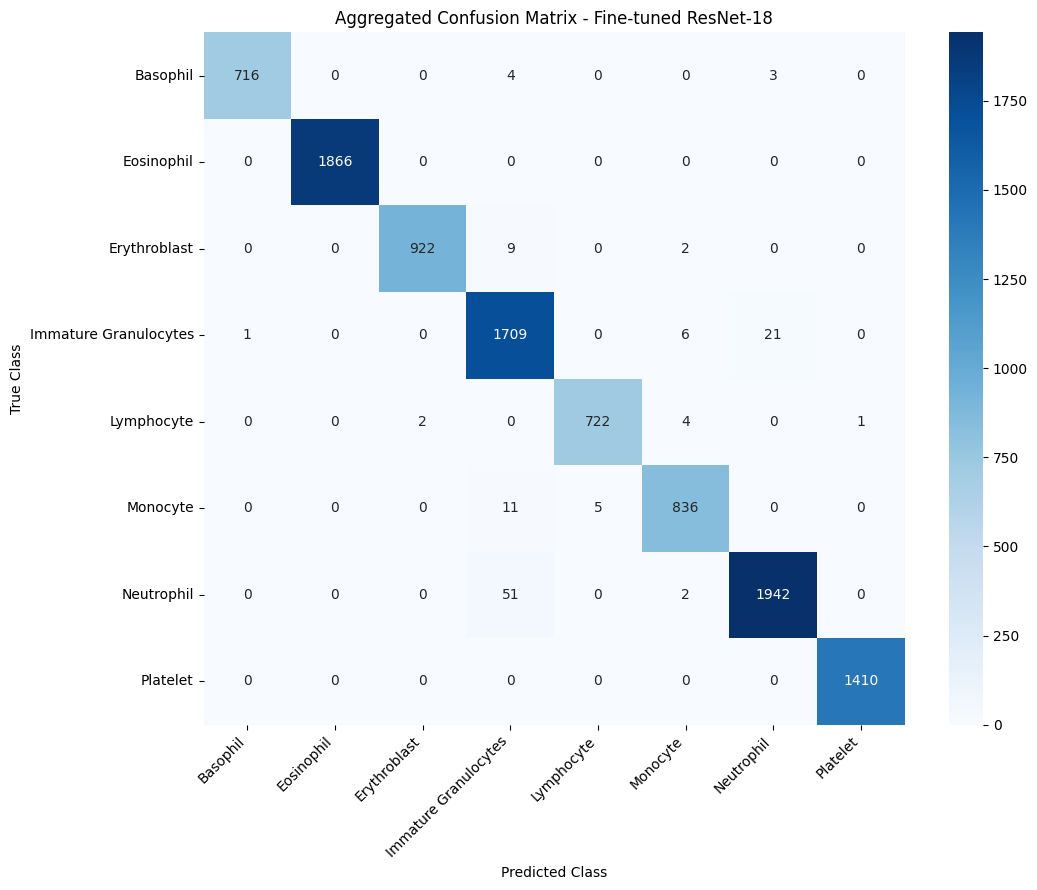

Aggregated confusion matrix generated successfully.


In [72]:
import os

# Create the figures directory if it does not already exist
os.makedirs("figures", exist_ok=True)


# Initialise an empty matrix to accumulate confusion matrices
# Rows represent true classes and columns represent predicted classes
aggregated_cm = np.zeros(
    (len(CLASS_NAMES), len(CLASS_NAMES)),
    dtype=int
)


# Generate and combine confusion matrices from all three random seeds
for seed in RANDOM_SEEDS:

    # Retrieve true labels and predicted labels for the current seed
    y_true = test_results["finetuned"][seed]["y_true"]
    y_pred = test_results["finetuned"][seed]["y_pred"]

    # Generate the confusion matrix using a consistent class order
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=range(len(CLASS_NAMES))
    )

    # Add the current seed's confusion matrix to the aggregated matrix
    aggregated_cm += cm


# Create a figure for the aggregated confusion matrix
plt.figure(figsize=(11, 9))

# Display the aggregated confusion matrix as a heatmap
# Each cell represents the total number of predictions across three seeds
sns.heatmap(
    aggregated_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

# Add plot title and axis labels
plt.title("Aggregated Confusion Matrix - Fine-tuned ResNet-18")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")

# Rotate class labels to improve readability
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

# Adjust the layout to prevent overlapping labels
plt.tight_layout()

# Save the aggregated confusion matrix
plt.savefig(
    "figures/aggregated_finetuned_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

# Display the confusion matrix
plt.show()

print("Aggregated confusion matrix generated successfully.")


## 8.7 Interpreting Model Attention and Possible Shortcuts

Grad-CAM visualisations are examined to understand whether the model focuses on relevant blood cell structures or potentially relies on irrelevant background information. A random-weight sanity check is performed by comparing the Grad-CAM heatmap of the trained model with that of a randomly initialised ResNet-18 model. If the heatmaps differ, this provides evidence that the visual explanations depend on the learned model parameters.

### Grad-CAM Random-Weight Sanity Check

A randomly initialised ResNet-18 model is used to generate a Grad-CAM heatmap for the same test image and target class as the trained model. The resulting heatmaps are compared visually to examine whether the trained model's attention patterns depend on learned weights.

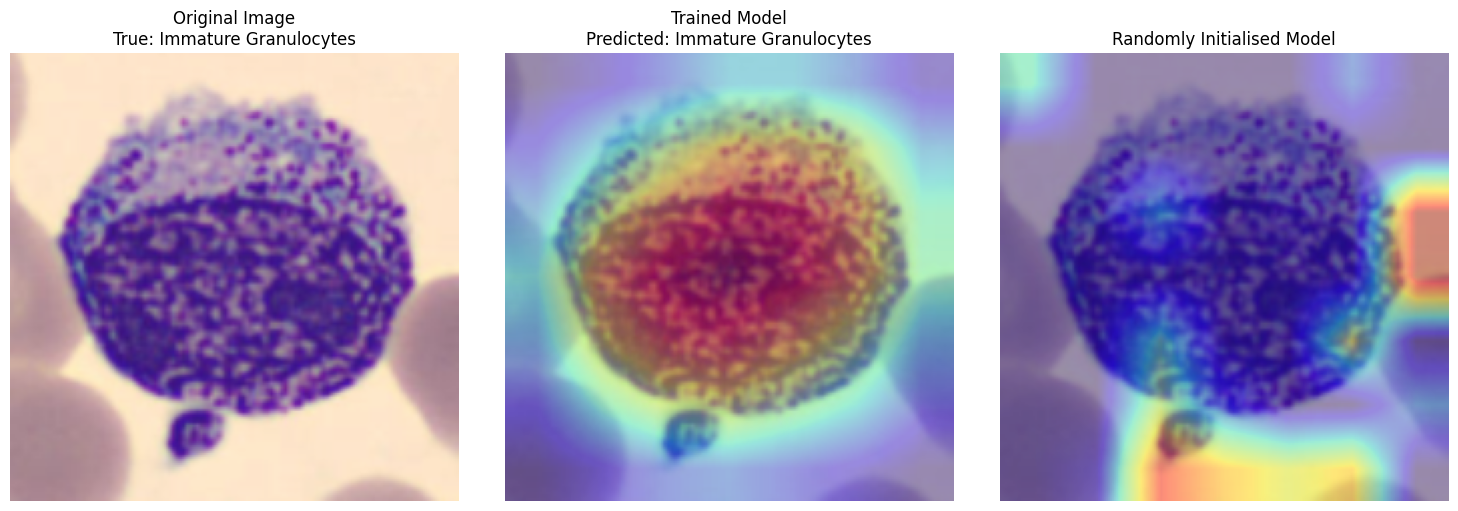

Mean absolute heatmap difference: 0.3978
Grad-CAM random-weight sanity check completed.


In [73]:
# Select one correctly classified test image for the sanity check
sample_idx = int(correct_indices[0])

image_tensor, true_label = test_dataset[sample_idx]
input_tensor = image_tensor.unsqueeze(0).to(DEVICE)

# Get the trained model's prediction
trained_model = finetuned_models[42]
trained_model.eval()

with torch.no_grad():
    trained_output = trained_model(input_tensor)
    trained_prediction = trained_output.argmax(dim=1).item()

# Reuse the Grad-CAM object created in Section 8.2
# It is already connected to the trained model's final convolutional layer
trained_heatmap, _ = gradcam.generate(
    input_tensor,
    class_idx=trained_prediction
)

# Create a randomly initialised ResNet-18
random_model = models.resnet18(weights=None)

# Replace the classification layer for eight blood cell classes
random_model.fc = nn.Linear(
    random_model.fc.in_features,
    len(CLASS_NAMES)
)

# Move the random model to the selected device and set evaluation mode
random_model = random_model.to(DEVICE)
random_model.eval()

# Create Grad-CAM for the randomly initialised model
random_gradcam = GradCAM(
    random_model,
    random_model.layer4[-1]
)

# Generate a heatmap for the same image and target class
random_heatmap, _ = random_gradcam.generate(
    input_tensor,
    class_idx=trained_prediction
)

# Convert the normalised image back to RGB
image = image_tensor.permute(1, 2, 0).cpu().numpy()
image = image * np.array(IMAGENET_STD) + np.array(IMAGENET_MEAN)
image = np.clip(image, 0, 1)

# Display the original image and both Grad-CAM heatmaps
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Original test image
axes[0].imshow(image)
axes[0].set_title(
    f"Original Image\nTrue: {CLASS_NAMES[true_label]}"
)
axes[0].axis("off")

# Grad-CAM from the trained model
axes[1].imshow(image)
axes[1].imshow(trained_heatmap, cmap="jet", alpha=0.4)
axes[1].set_title(
    f"Trained Model\nPredicted: {CLASS_NAMES[trained_prediction]}"
)
axes[1].axis("off")

# Grad-CAM from the randomly initialised model
axes[2].imshow(image)
axes[2].imshow(random_heatmap, cmap="jet", alpha=0.4)
axes[2].set_title("Randomly Initialised Model")
axes[2].axis("off")

plt.tight_layout()

# Save the comparison figure
plt.savefig(
    "figures/gradcam_random_weight_sanity_check.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Calculate the mean absolute difference between the heatmaps
heatmap_difference = np.mean(
    np.abs(trained_heatmap - random_heatmap)
)

print(
    f"Mean absolute heatmap difference: "
    f"{heatmap_difference:.4f}"
)

# Remove hooks after completing the Grad-CAM analysis
gradcam.remove_hooks()
random_gradcam.remove_hooks()

print("Grad-CAM random-weight sanity check completed.")

# 9. Results and Discussion

The experimental results demonstrate that fine-tuning ResNet-18 substantially improved BloodMNIST classification performance compared with using a frozen pretrained backbone. Across three random seeds, the fine-tuned model achieved a mean test accuracy of **98.81% ± 0.02%** and a macro F1-score of **98.91% ± 0.02%**, compared with **88.97% ± 0.22%** and **88.11% ± 0.60%**, respectively, for the frozen model.

Class-wise analysis showed improvements in F1-score across all eight blood cell categories. The most frequent classification error was the misclassification of neutrophils as immature granulocytes, with 51 errors across the three seeds. This suggests that distinguishing between these cell types remains challenging. For the selected focus class, immature granulocytes, mean recall improved from **84.80%** with the frozen model to **98.39%** with the fine-tuned model. The 95% bootstrap confidence intervals were 81.98–87.56% and 97.58–99.08%, respectively.

Paired bootstrap analysis further supported the improvement from fine-tuning. The 95% confidence interval for the accuracy improvement was 8.87–10.80 percentage points, while the interval for macro F1 improvement was 9.75–11.84 percentage points.

Grad-CAM visualisations were used to examine the image regions influencing the trained model's predictions. The random-weight sanity check provided a comparison with explanations generated from a model without learned training parameters.

Despite the strong results, this study is limited to the BloodMNIST dataset and its cleaned, predefined test split. Patient-level independence could not be verified because patient and source identifiers were unavailable. Further external validation across independent datasets, patient populations, imaging systems and staining protocols is necessary before considering real-world biomedical applications.

# 10. Conclusion and Future Work

This project compared frozen and fine-tuned ImageNet-pretrained ResNet-18 models for multiclass blood cell classification using the BloodMNIST dataset.

Across three random seeds, the fine-tuned model achieved a mean test accuracy of 98.81% and a mean macro F1-score of 98.91%, outperforming the frozen model, which achieved 88.97% accuracy and 88.11% macro F1-score. These results demonstrate the benefit of adapting pretrained model parameters to the target dataset.

For the focus class, immature granulocytes, fine-tuning also substantially improved recall compared with the frozen approach. The results highlight the importance of evaluating class-specific performance alongside overall classification metrics.

Future work could explore other CNN architectures, additional data augmentation techniques, external dataset validation and further explainability methods to improve model reliability and generalisation. Evaluation on independent clinical datasets would be particularly important before considering real-world biomedical applications.

In [ ]:
import os
import zipfile

project_folder = os.getcwd()
zip_name = "BloodMNIST_ResNet18_Project.zip"

with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, files in os.walk(project_folder):
        # Avoid including the ZIP inside itself
        dirs[:] = [d for d in dirs if d != "__pycache__"]

        for file in files:
            file_path = os.path.join(root, file)

            if file == zip_name:
                continue

            arcname = os.path.relpath(file_path, project_folder)
            zipf.write(file_path, arcname)

print("ZIP created:", os.path.abspath(zip_name))
print("Size:", round(os.path.getsize(zip_name) / (1024**2), 2), "MB")